# Synchronizing strata

*A small transformer trained on a hidden Markov model with designed synchronizing words: what its activations
represent, how that is learned, and which measurements of it can be trusted.*

This notebook reproduces and checks an earlier write-up of the same setup. It is a baseline: the hidden process
is a plug-in, so the interesting use is to change it and rerun (last sections).

**What is in it**

1. A 4-state, 6-token HMM with a rank-1 word `s` (every history collapses to one belief), a rank-2 word `f`
   (beliefs collapse onto a segment) and four full-rank "fold" tokens.
2. A 143,846-parameter transformer (4 layers, d=64, one 8-dim head per layer) trained on fresh samples.
3. Exact tools: the Bayes belief, the optimal next-token distribution, KL to it, all computed analytically.
4. Measurements: excess KL, a linear belief probe, spread of the point stratum, a history probe,
   learning order across checkpoints, and error inheritance.
5. What did **not** work (a local-dimension estimator), with the calibration that shows why.

**Headline results** (3 seeds, 40k steps; the notebook regenerates a fast single-seed version in minutes)

* The model reaches the Bayes-optimal predictor to within about 0.09 x 10^-3 nats per token, and its final
  residual stream linearly encodes the belief state (R² > 0.995).
* After the rank-1 word the activations are much tighter than after a fold token (variance ratio 0.03 to 0.06),
  but they are not a point: the residual stream keeps pre-sync history, decodable for a few steps.
* The coarse next-token surface is learned before the belief geometry; the last order of magnitude of KL arrives
  after the belief probe has saturated, together with the surplus history.
* Error inheritance (does the model build belief t+1 from its belief at t?) is large at initialisation and mostly
  gone, but not entirely, by the end.

**Caveats** are in the last section. In particular: one HMM, one architecture, three seeds, and all thresholds
in the learning-order analysis are choices.

## 0. Setup

The package is written by the next cell (collapsed: it is plain Python, about 800 lines). Set `MODE` below.
`fast` trains one seed for 5,000 steps (a few minutes on a Colab GPU); `full` trains three seeds for 40,000
steps (tens of minutes on a GPU, far too slow on CPU). A GPU runtime is recommended. The stored outputs were
produced in fast mode on an Intel Arc GPU (device `xpu`); on Colab the device is `cuda`.

In [1]:
#@title Package code (click to expand)
import os, sys, pathlib
FILES = {'hmmstrata/__init__.py': '', 'hmmstrata/device.py': 'import torch\n\n\ndef pick() -> str:\n    """cuda (Colab GPU), else Intel xpu, else cpu."""\n    if torch.cuda.is_available():\n        return "cuda"\n    if hasattr(torch, "xpu") and torch.xpu.is_available():\n        return "xpu"\n    return "cpu"\n', 'hmmstrata/exact.py': '"""Exact (analytic) tools for any HMM: sampling, beliefs, Bayes predictor, ground truth."""\nfrom __future__ import annotations\nimport numpy as np\nfrom .process.base import HMM\n\n\ndef sample(hmm: HMM, n: int, length: int, rng: np.random.Generator):\n    """Returns tokens (n, length) and states (n, length): state before emitting token t."""\n    V, S = hmm.V, hmm.S\n    # joint (token, next_state) distribution per state, flattened\n    J = hmm.T.transpose(1, 0, 2).reshape(S, V * S)\n    C = np.cumsum(J, axis=1)\n    state = rng.choice(S, size=n, p=hmm.pi0)\n    toks = np.empty((n, length), dtype=np.int64)\n    sts = np.empty((n, length), dtype=np.int64)\n    for t in range(length):\n        sts[:, t] = state\n        u = rng.random(n)[:, None]\n        k = (u > C[state]).sum(axis=1)\n        k = np.minimum(k, V * S - 1)\n        toks[:, t] = k // S\n        state = k % S\n    return toks, sts\n\n\ndef beliefs(hmm: HMM, tokens: np.ndarray):\n    """For each position t: eta[t] = posterior over the hidden state *after* tokens[:t+1]\n    (the state before emitting token t+1), and probs[t] = P(token t+1 | tokens[:t+1]).\n    Also returns the prior prediction for token 0 as prior_probs (V,)."""\n    n, L = tokens.shape\n    eta = np.empty((n, L, hmm.S))\n    probs = np.empty((n, L, hmm.V))\n    emit = hmm.T.sum(axis=2)  # (V, S): P(token | state)\n    cur = np.broadcast_to(hmm.pi0, (n, hmm.S)).copy()\n    for t in range(L):\n        new = np.einsum("ni,nij->nj", cur, hmm.T[tokens[:, t]])\n        new /= new.sum(axis=1, keepdims=True)\n        eta[:, t] = new\n        probs[:, t] = new @ emit.T\n        cur = new\n    prior_probs = hmm.pi0 @ emit.T\n    return eta, probs, prior_probs\n\n\ndef entropy(p: np.ndarray, axis: int = -1) -> np.ndarray:\n    q = np.where(p > 0, p, 1.0)\n    return -(p * np.log(q)).sum(axis=axis)\n\n\ndef tail_mass(p: np.ndarray, k: int) -> np.ndarray:\n    """Probability mass outside the top-k tokens."""\n    s = np.sort(p, axis=-1)[..., ::-1]\n    return 1.0 - s[..., :k].sum(axis=-1)\n\n\ndef steps_since(tokens: np.ndarray, token_set: set[int]) -> np.ndarray:\n    """(n, L): steps since the last token in token_set at or before position t (0 = token t\n    itself); -1 if none yet."""\n    n, L = tokens.shape\n    hit = np.isin(tokens, list(token_set))\n    out = np.full((n, L), -1, dtype=np.int64)\n    last = np.full(n, -10**9)\n    for t in range(L):\n        last = np.where(hit[:, t], t, last)\n        out[:, t] = np.where(last >= 0, t - last, -1)\n    return out\n\n\ndef steps_until_state(states: np.ndarray, state_set: set[int], after: int = 1) -> np.ndarray:\n    """(n, L): steps from position t until the hidden state at some later position is in\n    state_set (state[t+after] ...); -1 if not within the window."""\n    n, L = states.shape\n    hit = np.isin(states, list(state_set))\n    out = np.full((n, L), -1, dtype=np.int64)\n    nxt = np.full(n, -1)\n    for t in range(L - 1, -1, -1):\n        out[:, t] = np.where(nxt >= 0, nxt - t, -1)\n        nxt = np.where(hit[:, t], t, nxt)\n    return out\n\n\ndef kl(p: np.ndarray, q: np.ndarray, axis: int = -1, eps: float = 1e-12) -> np.ndarray:\n    pp = np.where(p > 0, p, 1.0)\n    return (p * (np.log(pp) - np.log(np.maximum(q, eps)))).sum(axis=axis)\n', 'hmmstrata/model.py': '"""Small pre-LN GPT, Shai et al. style: n_layers x (1 head of d_head, ReLU MLP)."""\nimport torch, torch.nn as nn, torch.nn.functional as F\n\n\nclass Block(nn.Module):\n    def __init__(self, d, n_heads, d_head, d_mlp):\n        super().__init__()\n        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)\n        self.nh, self.dh = n_heads, d_head\n        self.qkv = nn.Linear(d, 3 * n_heads * d_head)\n        self.o = nn.Linear(n_heads * d_head, d)\n        self.fc1, self.fc2 = nn.Linear(d, d_mlp), nn.Linear(d_mlp, d)\n\n    def forward(self, x):\n        B, T, _ = x.shape\n        q, k, v = self.qkv(self.ln1(x)).view(B, T, 3, self.nh, self.dh).permute(2, 0, 3, 1, 4)\n        a = F.scaled_dot_product_attention(q, k, v, is_causal=True)\n        x = x + self.o(a.transpose(1, 2).reshape(B, T, -1))\n        return x + self.fc2(F.relu(self.fc1(self.ln2(x))))\n\n\nclass GPT(nn.Module):\n    def __init__(self, vocab, ctx=16, d=64, n_layers=4, n_heads=1, d_head=8, d_mlp=256):\n        super().__init__()\n        self.cfg = dict(vocab=vocab, ctx=ctx, d=d, n_layers=n_layers, n_heads=n_heads,\n                        d_head=d_head, d_mlp=d_mlp)\n        self.tok, self.pos = nn.Embedding(vocab, d), nn.Embedding(ctx, d)\n        self.blocks = nn.ModuleList(Block(d, n_heads, d_head, d_mlp) for _ in range(n_layers))\n        self.lnf, self.head = nn.LayerNorm(d), nn.Linear(d, vocab)\n\n    def forward(self, idx, return_resid=False):\n        """return_resid: False | True (final residual) | \'all\' (list: embedding + after each block)."""\n        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1], device=idx.device))\n        allr = [x]\n        for b in self.blocks:\n            x = b(x)\n            allr.append(x)\n        logits = self.head(self.lnf(x))\n        if return_resid == "all":\n            return logits, allr\n        return (logits, x) if return_resid else logits\n', 'hmmstrata/train.py': '"""Train a GPT on fresh samples of a registered process; log-spaced checkpoints."""\nimport argparse, json, math, time\nfrom pathlib import Path\nimport numpy as np, torch, torch.nn.functional as F\nfrom .process import make\nfrom . import exact\nfrom .model import GPT\n\n\ndef log_steps(total: int, n: int = 24) -> list[int]:\n    s = {0, total} | {int(round(x)) for x in np.geomspace(1, total, n)}\n    return sorted(s)\n\n\ndef device(name: str):\n    return torch.device(name)\n\n\ndef train(process: str, pparams: dict, seed: int, steps: int, out: Path, dev: str = "cpu",\n          ctx: int = 16, batch: int = 128, lr: float = 1e-3, model_kw: dict | None = None,\n          n_ckpt: int = 24, wd: float = 0.01):\n    hmm = make(process, **pparams)\n    torch.manual_seed(seed)\n    rng = np.random.default_rng(seed)\n    model = GPT(hmm.V, ctx=ctx, **(model_kw or {})).to(dev)\n    nparams = sum(p.numel() for p in model.parameters())\n    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)\n    sched = torch.optim.lr_scheduler.LambdaLR(\n        opt, lambda s: 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps)))\n    out.mkdir(parents=True, exist_ok=True)\n    (out / "config.json").write_text(json.dumps(dict(\n        process=process, pparams=pparams, seed=seed, steps=steps, ctx=ctx, batch=batch, lr=lr,\n        model=model.cfg, n_params=nparams, device=dev, wd=wd), indent=1))\n    ckpts = set(log_steps(steps, n_ckpt))\n    log = open(out / "train_log.jsonl", "w")\n    t0 = time.time()\n\n    def save(step):\n        torch.save(model.state_dict(), out / f"ckpt_{step:06d}.pt")\n\n    for step in range(steps + 1):\n        if step in ckpts:\n            save(step)\n        if step == steps:\n            break\n        toks, _ = exact.sample(hmm, batch, ctx + 1, rng)\n        x = torch.from_numpy(toks).to(dev)\n        loss = F.cross_entropy(model(x[:, :-1]).reshape(-1, hmm.V), x[:, 1:].reshape(-1))\n        opt.zero_grad(set_to_none=True)\n        loss.backward()\n        opt.step(); sched.step()\n        if step % 500 == 0:\n            log.write(json.dumps(dict(step=step, loss=loss.item(), t=time.time() - t0)) + "\\n"); log.flush()\n    return nparams\n\n\nif __name__ == "__main__":\n    ap = argparse.ArgumentParser()\n    ap.add_argument("--process", default="sync_strata")\n    ap.add_argument("--seed", type=int, default=0)\n    ap.add_argument("--steps", type=int, default=40000)\n    ap.add_argument("--device", default="cpu")\n    ap.add_argument("--out", required=True)\n    ap.add_argument("--wd", type=float, default=0.01)\n    ap.add_argument("--pparams", default="{}")\n    a = ap.parse_args()\n    print("params", train(a.process, json.loads(a.pparams), a.seed, a.steps, Path(a.out), a.device, wd=a.wd))\n', 'hmmstrata/analyze.py': '"""Metrics for one checkpoint: surface (KL to Bayes) and geometry (probe, point stratum)."""\nimport argparse, json\nfrom pathlib import Path\nimport numpy as np, torch\nfrom .process import make\nfrom . import exact\nfrom .model import GPT\n\n\ndef load(run: Path, step: int | None = None, dev="cpu"):\n    cfg = json.loads((run / "config.json").read_text())\n    hmm = make(cfg["process"], **cfg["pparams"])\n    ck = sorted(run.glob("ckpt_*.pt"))\n    path = ck[-1] if step is None else run / f"ckpt_{step:06d}.pt"\n    m = GPT(**cfg["model"]).to(dev)\n    m.load_state_dict(torch.load(path, map_location=dev)); m.eval()\n    return hmm, m, cfg, path\n\n\n@torch.no_grad()\ndef run_model(m, toks, dev, bs=4096):\n    P, R = [], []\n    for i in range(0, len(toks), bs):\n        lg, r = m(torch.from_numpy(toks[i:i + bs]).to(dev), return_resid=True)\n        P.append(torch.softmax(lg.float(), -1).cpu().numpy()); R.append(r.float().cpu().numpy())\n    return np.concatenate(P), np.concatenate(R)\n\n\ndef ridge_r2(X, Y, seed=0, lam=1e-3):\n    rng = np.random.default_rng(seed)\n    idx = rng.permutation(len(X)); k = int(0.8 * len(X))\n    tr, te = idx[:k], idx[k:]\n    Xa = np.hstack([X, np.ones((len(X), 1))])\n    A = Xa[tr].T @ Xa[tr] + lam * np.eye(Xa.shape[1])\n    W = np.linalg.solve(A, Xa[tr].T @ Y[tr])\n    res = Y[te] - Xa[te] @ W\n    return 1 - (res ** 2).sum() / ((Y[te] - Y[te].mean(0)) ** 2).sum()\n\n\ndef analyze(run: Path, step=None, n=20000, seed=123, dev="cpu"):\n    hmm, m, cfg, path = load(run, step, dev)\n    ctx = cfg["ctx"]\n    toks, _ = exact.sample(hmm, n, ctx + 1, np.random.default_rng(seed))\n    x = toks[:, :ctx]\n    eta, bayes, _ = exact.beliefs(hmm, x)\n    probs, resid = run_model(m, x, dev)\n    kl = exact.kl(bayes, probs)                       # (n, ctx)\n    s_tok, f_tok = hmm.token_names.index("s"), hmm.token_names.index("f")\n    since_sync = exact.steps_since(x, {s_tok, f_tok})\n    since_s = exact.steps_since(x, {s_tok})\n    out = {"ckpt": path.name, "excess_kl_nats": float(kl.mean())}\n    out["kl_e3_by_since_sync"] = {int(k): float(1e3 * kl[since_sync == k].mean())\n                                  for k in (0, 1, 2, 4, 8) if (since_sync == k).any()}\n    out["kl_e3_s0"] = float(1e3 * kl[since_s == 0].mean())\n    out["kl_e3_f0"] = float(1e3 * kl[(since_sync == 0) & (x == f_tok)].mean())\n    pos = np.arange(ctx)[None, :] >= 6\n    sel = np.ones_like(kl, bool)\n    out["probe_r2_all"] = float(ridge_r2(resid.reshape(-1, resid.shape[-1])[::2], eta.reshape(-1, hmm.S)[::2]))\n    # point stratum vs token-matched control (same last token 0, deep after a sync)\n    tot_var = lambda A: float(np.trace(np.cov(A.T)))\n    g_s = resid[(x == s_tok) & pos]\n    g_c = resid[(x == 0) & (since_sync >= 6) & pos]\n    out["var_s"], out["var_token0_deep"] = tot_var(g_s), tot_var(g_c)\n    out["point_ratio"] = out["var_s"] / out["var_token0_deep"]\n    # earlier write-up\'s convention: centre each group at a fixed position, average over positions 6..15\n    def pos_var(mask_fn, hi=15):\n        v = []\n        for t in range(6, hi):\n            A = resid[mask_fn(t), t]\n            if len(A) > 30:\n                v.append(np.trace(np.cov(A.T)))\n        return float(np.mean(v))\n    vs = pos_var(lambda t: x[:, t] == s_tok)\n    vc = pos_var(lambda t: (x[:, t] == 0) & (since_sync[:, t] >= 5))\n    out["point_ratio_perpos_6_14"] = vs / vc          # positions 6..14, as in the earlier write-up\n    out["point_ratio_perpos_6_15"] = pos_var(lambda t: x[:, t] == s_tok, ctx) / pos_var(\n        lambda t: (x[:, t] == 0) & (since_sync[:, t] >= 5), ctx)\n    return out\n\n\nif __name__ == "__main__":\n    ap = argparse.ArgumentParser()\n    ap.add_argument("run"); ap.add_argument("--step", type=int); ap.add_argument("--device", default="cpu")\n    a = ap.parse_args()\n    print(json.dumps(analyze(Path(a.run), a.step, dev=a.device), indent=1))\n', 'hmmstrata/inherit.py': '"""Error inheritance: does the model\'s belief error at t+1 carry the error at t, pushed through\nthe true update map?  A model folding recursively (belief_{t+1} = f_x(belief_t)) passes errors\nalong: corr ~ 1.  A model computing every position afresh from the context: corr ~ 0.\n\nPairs (t, t+1) with the last sync an `s` at depth k (steps since s at t, k = 1..K) and a fold\ntoken x at t+1.  e_t = probe_t - eta_t.  propagated = e_t @ J_x(eta_t) with the Jacobian of the\ntrue update f_x(eta) = eta T_x / (eta T_x 1):   J[i,j] = (T_x[i,j] - r_i f_j) / s,  r = T_x 1.\nScore = Pearson correlation between propagated and e_{t+1} (all components pooled), against a\ncontrol that shuffles e_{t+1} among the pairs of the same depth."""\nimport argparse\nfrom pathlib import Path\nimport numpy as np\nfrom . import exact\nfrom .analyze import load, run_model\n\n\ndef jacobian_push(hmm, eta, x_next, e):\n    Tx = hmm.T[x_next]                                   # (n, S, S)\n    u = np.einsum("ni,nij->nj", eta, Tx)\n    s = u.sum(1)\n    f = u / s[:, None]\n    r = Tx.sum(2)\n    J = (Tx - r[:, :, None] * f[:, None, :]) / s[:, None, None]\n    return np.einsum("ni,nij->nj", e, J)\n\n\ndef corr(a, b):\n    a, b = a.ravel() - a.mean(), b.ravel() - b.mean()\n    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))\n\n\ndef inheritance_from_estimates(hmm, x, eta, est, depths=range(1, 7), seed=0):\n    """x (n,L) tokens, eta (n,L,S) true beliefs, est (n,L,S) estimated beliefs."""\n    rng = np.random.default_rng(seed)\n    s_tok = hmm.token_names.index("s")\n    sync = {hmm.token_names.index(t) for t in ("s", "f")}\n    since_s = exact.steps_since(x, {s_tok})\n    since_any = exact.steps_since(x, sync)\n    fold = x < s_tok\n    out = {}\n    for k in depths:\n        sel = (since_s[:, :-1] == k) & (since_any[:, :-1] == k) & fold[:, 1:]\n        ni, ti = np.nonzero(sel)\n        if len(ni) < 200:\n            continue\n        e_t = est[ni, ti] - eta[ni, ti]\n        e_n = est[ni, ti + 1] - eta[ni, ti + 1]\n        prop = jacobian_push(hmm, eta[ni, ti], x[ni, ti + 1], e_t)\n        out[k] = (corr(prop, e_n), corr(prop, e_n[rng.permutation(len(e_n))]), len(ni))\n    return out\n\n\ndef fit_probe(R, eta, lam=1e-3):\n    X = np.hstack([R.reshape(-1, R.shape[-1]), np.ones((R.shape[0] * R.shape[1], 1))]).astype(np.float64)\n    return np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T @ eta.reshape(-1, eta.shape[-1]))\n\n\ndef apply_probe(W, R):\n    X = np.concatenate([R, np.ones(R.shape[:-1] + (1,))], -1).astype(np.float64)\n    return X @ W\n\n\ndef inheritance(run_dir: Path, step=None, n=40000, dev="cpu", depths=range(1, 7)):\n    hmm, m, cfg, path = load(run_dir, step, dev)\n    ctx = cfg["ctx"]\n    xf = exact.sample(hmm, n, ctx, np.random.default_rng(11))[0]\n    ef, _, _ = exact.beliefs(hmm, xf)\n    _, rf = run_model(m, xf, dev)\n    W = fit_probe(rf, ef)\n    x = exact.sample(hmm, n, ctx, np.random.default_rng(7))[0]\n    eta, _, _ = exact.beliefs(hmm, x)\n    _, r = run_model(m, x, dev)\n    return inheritance_from_estimates(hmm, x, eta, apply_probe(W, r), depths)\n\n\nif __name__ == "__main__":\n    ap = argparse.ArgumentParser()\n    ap.add_argument("run"); ap.add_argument("--step", type=int); ap.add_argument("--device", default="cpu")\n    a = ap.parse_args()\n    res = inheritance(Path(a.run), a.step, dev=a.device)\n    print("depth  corr(real)  corr(shuffled)  n")\n    for k, (c, cs, nn) in res.items():\n        print(f"{k:5d}  {c:9.3f}  {cs:12.3f}  {nn}")\n', 'hmmstrata/probes.py': '"""Extended probes: belief R2 and pre-sync-token decoding, across layers, steps-since-s, and\ncheckpoints. The true belief after s is a single point, so the pre-sync token carries no\ninformation about the future: any decoding above the majority baseline is surplus history."""\nimport json, sys\nfrom pathlib import Path\nimport numpy as np, torch\nfrom . import exact\nfrom .analyze import load, ridge_r2\n\n\n@torch.no_grad()\ndef collect(m, x, dev, bs=4096):\n    out = None\n    for i in range(0, len(x), bs):\n        lg, rs = m(torch.from_numpy(x[i:i + bs]).to(dev), return_resid="all")\n        rs = [r.float().cpu().numpy() for r in rs]\n        P = torch.softmax(lg.float(), -1).cpu().numpy()\n        if out is None:\n            out = ([[] for _ in rs], [])\n        for j, r in enumerate(rs):\n            out[0][j].append(r)\n        out[1].append(P)\n    return [np.concatenate(a) for a in out[0]], np.concatenate(out[1])\n\n\ndef decode_acc(X, y, V, lam=1e-2, seed=0):\n    idx = np.random.default_rng(seed).permutation(len(X)); k = int(0.8 * len(X))\n    tr, te = idx[:k], idx[k:]\n    Xa = np.hstack([X, np.ones((len(X), 1))]).astype(np.float64)\n    Y = np.eye(V)[y]\n    W = np.linalg.solve(Xa[tr].T @ Xa[tr] + lam * np.eye(Xa.shape[1]), Xa[tr].T @ Y[tr])\n    acc = (np.argmax(Xa[te] @ W, 1) == y[te]).mean()\n    base = (y[te] == np.bincount(y[tr], minlength=V).argmax()).mean()\n    return float(acc), float(base)\n\n\ndef presync(layers, x, V, s_tok, k, layer):\n    n, L = x.shape\n    since = exact.steps_since(x, {s_tok})\n    mask = (since == k) & (np.arange(L)[None, :] >= k + 1)\n    ni, ti = np.nonzero(mask)\n    return layers[layer][ni, ti], x[ni, ti - k - 1]\n\n\ndef evaluate(run_dir, step=None, n=25000, dev="xpu", ks=(1, 2, 3, 4, 6, 8), layers_k=2):\n    hmm, m, cfg, path = load(run_dir, step, dev)\n    x = exact.sample(hmm, n, cfg["ctx"] + 1, np.random.default_rng(5))[0][:, :cfg["ctx"]]\n    eta, bayes, _ = exact.beliefs(hmm, x)\n    layers, probs = collect(m, x, dev)\n    s_tok = hmm.token_names.index("s")\n    res = dict(ckpt=path.name, kl_e3=float(1e3 * exact.kl(bayes, probs).mean()))\n    res["belief_r2"] = [float(ridge_r2(l.reshape(-1, l.shape[-1])[::3], eta.reshape(-1, hmm.S)[::3])) for l in layers]\n    res["presync_final"] = {}\n    for k in ks:\n        X, y = presync(layers, x, hmm.V, s_tok, k, -1)\n        res["presync_final"][k] = decode_acc(X, y, hmm.V) + (len(y),)\n    res["presync_layers"] = [decode_acc(*presync(layers, x, hmm.V, s_tok, layers_k, l), hmm.V) for l in range(len(layers))]\n    return res\n\n\nif __name__ == "__main__":\n    for s in (0, 1, 2):\n        r = evaluate(Path(f"runs/control_sync_strata/s{s}"))\n        print(f"\\nseed {s} final: belief R2 by stream (emb,L1..L4): " + " ".join(f"{v:.3f}" for v in r["belief_r2"]))\n        print("  pre-sync token decode at final layer (acc / majority baseline, n):")\n        for k, (a, b, nn) in r["presync_final"].items():\n            print(f"    k={k}: {a:.3f} / {b:.3f}  (n={nn})")\n        print("  k=2 by stream (emb,L1..L4): " + " ".join(f"{a:.2f}/{b:.2f}" for a, b in r["presync_layers"]))\n', 'hmmstrata/series.py': '"""Metrics across all checkpoints of a run -> series.json; 90%-of-improvement step per metric."""\nimport json, sys\nfrom pathlib import Path\nimport numpy as np\nfrom .probes import evaluate\n\n\ndef series(run: Path, n=12000, dev="xpu"):\n    out = []\n    for p in sorted(run.glob("ckpt_*.pt")):\n        s = int(p.stem.split("_")[1])\n        r = evaluate(run, s, n=n, dev=dev, ks=(2, 4), layers_k=2)\n        out.append(dict(step=s, kl_e3=r["kl_e3"], belief_r2=r["belief_r2"][-1],\n                        hist_k2=r["presync_final"][2][0], hist_k4=r["presync_final"][4][0]))\n    (run / "series.json").write_text(json.dumps(out, indent=1))\n    return out\n\n\ndef t90(steps, vals, frac=0.9):\n    v = np.array(vals, float); v0, v1 = v[0], v[-1]\n    prog = (v - v0) / (v1 - v0)\n    return int(steps[int(np.argmax(prog >= frac))])\n\n\ndef summary(out):\n    st = [o["step"] for o in out]\n    return {k: t90(st, [o[k] for o in out]) for k in ("kl_e3", "belief_r2", "hist_k2")}\n\n\nif __name__ == "__main__":\n    for s in map(int, sys.argv[1:]):\n        run = Path(f"runs/control_sync_strata/s{s}")\n        out = series(run)\n        print(f"seed {s}: 90% step {summary(out)}  hist_k2 {out[0][\'hist_k2\']:.2f}->{out[-1][\'hist_k2\']:.2f}  hist_k4 {out[0][\'hist_k4\']:.2f}->{out[-1][\'hist_k4\']:.2f}", flush=True)\n', 'hmmstrata/localdim.py': '"""Local intrinsic dimension (TwoNN and Levina-Bickel MLE) per context group, for the model\'s\nresidual stream and for the true belief vectors on the same contexts."""\nimport argparse, json\nfrom pathlib import Path\nimport numpy as np\nfrom scipy.spatial import cKDTree\nfrom . import exact\nfrom .analyze import load, run_model\n\n\ndef _dedup(X, decimals=7):\n    _, i = np.unique(np.round(X, decimals), axis=0, return_index=True)\n    return X[np.sort(i)]\n\n\ndef twonn(X, max_pts=20000, trim=0.1, seed=0):\n    """Facco et al. 2017: d = N / sum log(r2/r1), top `trim` fraction of ratios discarded."""\n    X = _dedup(X)\n    if len(X) < 50:\n        return float("nan"), len(X)\n    if len(X) > max_pts:\n        X = X[np.random.default_rng(seed).choice(len(X), max_pts, replace=False)]\n    d, _ = cKDTree(X).query(X, k=3)\n    r1, r2 = d[:, 1], d[:, 2]\n    ok = r1 > 0\n    mu = np.sort(r2[ok] / r1[ok])\n    mu = mu[: int(len(mu) * (1 - trim))]\n    return float(len(mu) / np.log(mu).sum()), len(X)\n\n\ndef mle_dim(X, k=10, max_pts=20000, seed=0):\n    """Levina-Bickel 2004 MLE with k neighbours, averaged over points."""\n    X = _dedup(X)\n    if len(X) < 2 * k:\n        return float("nan")\n    if len(X) > max_pts:\n        X = X[np.random.default_rng(seed).choice(len(X), max_pts, replace=False)]\n    d, _ = cKDTree(X).query(X, k=k + 1)\n    d = d[:, 1:]\n    d = d[d[:, 0] > 0]\n    inv = np.log(d[:, -1:] / d[:, :-1]).sum(1) / (k - 1)\n    return float(1.0 / inv.mean())\n\n\ndef groups(x, hmm, t):\n    s, f = hmm.token_names.index("s"), hmm.token_names.index("f")\n    sync = exact.steps_since(x, {s, f})\n    since_s = exact.steps_since(x, {s})\n    col = x[:, t]\n    g = {"ends in s (rank 1)": col == s, "ends in f (rank 2)": col == f}\n    for k in (1, 2, 3):\n        g[f"token 0, {k} after s"] = (col == 0) & (since_s[:, t] == k)\n    g["token 0, >=6 after any sync"] = (col == 0) & (sync[:, t] >= 6)\n    return g\n\n\ndef run(run_dir: Path, step=None, n=200000, t=12, seed=7, dev="xpu"):\n    hmm, m, cfg, path = load(run_dir, step, dev)\n    x = exact.sample(hmm, n, cfg["ctx"], np.random.default_rng(seed))[0]\n    eta, _, _ = exact.beliefs(hmm, x)\n    _, resid = run_model(m, x, dev)\n    rows = []\n    for name, mask in groups(x, hmm, t).items():\n        A, B = resid[mask, t].astype(np.float64), eta[mask, t]\n        da, na = twonn(A); db, nb = twonn(B)\n        rows.append(dict(group=name, n=int(mask.sum()), n_unique_belief=int(len(_dedup(B))),\n                         act_twonn=da, act_mle=mle_dim(A), belief_twonn=db, belief_mle=mle_dim(B)))\n    return dict(ckpt=path.name, position=t, rows=rows)\n\n\nif __name__ == "__main__":\n    ap = argparse.ArgumentParser()\n    ap.add_argument("run"); ap.add_argument("--step", type=int); ap.add_argument("--device", default="xpu")\n    a = ap.parse_args()\n    r = run(Path(a.run), a.step, dev=a.device)\n    print(r["ckpt"], "position", r["position"])\n    print(f"{\'group\':32s} {\'n\':>6s} {\'uniq_b\':>6s} | {\'act TwoNN\':>9s} {\'act MLE\':>8s} | {\'bel TwoNN\':>9s} {\'bel MLE\':>8s}")\n    for w in r["rows"]:\n        print(f"{w[\'group\']:32s} {w[\'n\']:6d} {w[\'n_unique_belief\']:6d} | {w[\'act_twonn\']:9.2f} {w[\'act_mle\']:8.2f} | {w[\'belief_twonn\']:9.2f} {w[\'belief_mle\']:8.2f}")\n', 'hmmstrata/split.py': '"""Split the residual stream into the belief-aligned subspace (span of the linear probe\'s\ndirections) and its orthogonal complement; local dimension of each, per context group,\nplus a scale-resolved correlation-dimension slope."""\nimport argparse\nfrom pathlib import Path\nimport numpy as np\nfrom scipy.spatial import cKDTree\nfrom . import exact\nfrom .analyze import load, run_model\nfrom .localdim import twonn, mle_dim, groups, _dedup\n\n\ndef probe_basis(resid, eta, lam=1e-3):\n    X = resid.reshape(-1, resid.shape[-1]).astype(np.float64)\n    Y = eta.reshape(-1, eta.shape[-1])\n    mu = X.mean(0)\n    Xc = X - mu\n    W = np.linalg.solve(Xc.T @ Xc + lam * np.eye(X.shape[1]), Xc.T @ (Y - Y.mean(0)))  # (d, S)\n    u, s, _ = np.linalg.svd(W, full_matrices=False)\n    k = int((s > 1e-6 * s[0]).sum())\n    return mu, u[:, :k]          # orthonormal basis of the probe\'s directions (rank <= S-1)\n\n\ndef corr_slopes(X, mults=(2, 4, 8, 16, 32), max_pts=4000, seed=0):\n    X = _dedup(X)\n    if len(X) < 200:\n        return [float("nan")] * len(mults)\n    if len(X) > max_pts:\n        X = X[np.random.default_rng(seed).choice(len(X), max_pts, replace=False)]\n    tree = cKDTree(X)\n    nn = np.median(tree.query(X, k=2)[0][:, 1])\n    r = nn * np.array(mults, float)\n    C = tree.count_neighbors(tree, r).astype(float) - len(X)\n    lo = tree.count_neighbors(tree, r / 1.5).astype(float) - len(X)\n    return [float(np.log(C[i] / max(lo[i], 1)) / np.log(1.5)) for i in range(len(r))]\n\n\ndef run(run_dir: Path, step=None, n=200000, t=12, seed=7, dev="xpu"):\n    hmm, m, cfg, path = load(run_dir, step, dev)\n    # probe fitted on a separate sample (all positions), so the split is not tuned to the groups\n    xt = exact.sample(hmm, 20000, cfg["ctx"], np.random.default_rng(11))[0]\n    et, _, _ = exact.beliefs(hmm, xt)\n    _, rt = run_model(m, xt, dev)\n    mu, Q = probe_basis(rt, et)\n    x = exact.sample(hmm, n, cfg["ctx"], np.random.default_rng(seed))[0]\n    eta, _, _ = exact.beliefs(hmm, x)\n    _, resid = run_model(m, x, dev)\n    sel = {k: v for k, v in groups(x, hmm, t).items()\n           if k in ("ends in s (rank 1)", "ends in f (rank 2)", "token 0, >=6 after any sync")}\n    print(f"{path.parent.name}/{path.name}  probe rank {Q.shape[1]}  position {t}")\n    print(f"{\'group\':30s} {\'space\':10s} {\'TwoNN\':>6s} {\'MLE\':>6s} | corr-dim slope at 2,4,8,16,32 x NN-scale")\n    for name, mask in sel.items():\n        R = resid[mask, t].astype(np.float64) - mu\n        parts = {"aligned": R @ Q, "orthogonal": R - (R @ Q) @ Q.T, "full": R, "belief": eta[mask, t]}\n        for sp, A in parts.items():\n            d, _ = twonn(A)\n            sl = corr_slopes(A)\n            print(f"{name:30s} {sp:10s} {d:6.2f} {mle_dim(A):6.2f} | " + " ".join(f"{v:5.2f}" for v in sl))\n\n\nif __name__ == "__main__":\n    ap = argparse.ArgumentParser()\n    ap.add_argument("run"); ap.add_argument("--step", type=int); ap.add_argument("--device", default="xpu")\n    a = ap.parse_args()\n    run(Path(a.run), a.step, dev=a.device)\n', 'hmmstrata/calibrate.py': '"""Calibrate the dimension estimators on synthetic sets of known dimension and noise,\nthen put subsampling error bars on the real slopes."""\nimport numpy as np\nfrom pathlib import Path\nfrom .localdim import twonn, mle_dim, groups\nfrom .split import corr_slopes, probe_basis\nfrom . import exact\nfrom .analyze import load, run_model\n\nMULTS = (2, 4, 8, 16, 32)\n\n\ndef synth(d, L, sigma, noise_dims=5, n=15000, D=64, seed=0):\n    rng = np.random.default_rng(seed)\n    lat = rng.random((n, d)) * L if d else np.zeros((n, 0))\n    Qm, _ = np.linalg.qr(rng.standard_normal((D, d + noise_dims)))\n    X = np.zeros((n, d + noise_dims))\n    X[:, :d] = lat\n    X[:, d:] = rng.standard_normal((n, noise_dims)) * sigma\n    return X @ Qm.T\n\n\ndef fmt(A):\n    sl = [corr_slopes(A, MULTS, seed=s) for s in range(8)]\n    m, sd = np.mean(sl, 0), np.std(sl, 0)\n    return " ".join(f"{a:4.2f}±{b:.2f}" for a, b in zip(m, sd))\n\n\ndef synthetic():\n    print("SYNTHETIC (noise: sigma=1 in 5 dims). cols: TwoNN MLE | slopes at 2,4,8,16,32 x NN")\n    for d, L in [(0, 1), (1, 20), (1, 100), (2, 20), (2, 100), (3, 100)]:\n        A = synth(d, L, 1.0)\n        print(f"true d={d} L={L:3d}  {twonn(A)[0]:5.2f} {mle_dim(A):5.2f} | {fmt(A)}")\n\n\ndef real(run_dir, t=12, n=200000, dev="xpu"):\n    hmm, m, cfg, path = load(run_dir, None, dev)\n    xt = exact.sample(hmm, 20000, cfg["ctx"], np.random.default_rng(11))[0]\n    et, _, _ = exact.beliefs(hmm, xt); _, rt = run_model(m, xt, dev)\n    mu, Q = probe_basis(rt, et)\n    x = exact.sample(hmm, n, cfg["ctx"], np.random.default_rng(7))[0]\n    eta, _, _ = exact.beliefs(hmm, x); _, resid = run_model(m, x, dev)\n    print(f"\\n{run_dir.name} (mean±sd over 8 subsamples)")\n    for name, mask in groups(x, hmm, t).items():\n        if name not in ("ends in s (rank 1)", "ends in f (rank 2)", "token 0, >=6 after any sync"):\n            continue\n        R = resid[mask, t].astype(np.float64) - mu\n        for sp, A in (("full", R), ("aligned", R @ Q)):\n            print(f"{name:28s} {sp:8s} {fmt(A)}")\n\n\nif __name__ == "__main__":\n    synthetic()\n    for s in (0, 1, 2):\n        real(Path(f"runs/control_sync_strata/s{s}"))\n', 'hmmstrata/process/__init__.py': 'from .base import HMM\nfrom .registry import register, make, names\n', 'hmmstrata/process/base.py': '"""Token-labelled HMM: the pluggable hidden process."""\nfrom __future__ import annotations\nfrom dataclasses import dataclass, field\nimport numpy as np\n\n\n@dataclass\nclass HMM:\n    """T[x, i, j] = P(emit token x and move to state j | state i).\n\n    sum_x T[x] must be row-stochastic. States are the hidden state *before* the\n    token at that position is emitted.\n    """\n    name: str\n    T: np.ndarray                      # (V, S, S)\n    pi0: np.ndarray                    # (S,)\n    state_names: list[str]\n    token_names: list[str]\n    state_groups: dict[str, set[int]] = field(default_factory=dict)\n    state_events: dict[str, set[int]] = field(default_factory=dict)   # hidden state in set\n    token_events: dict[str, set[int]] = field(default_factory=dict)   # emitted token in set\n    expected: dict = field(default_factory=dict)  # predictions written before training\n    params: dict = field(default_factory=dict)\n\n    @property\n    def V(self) -> int:\n        return self.T.shape[0]\n\n    @property\n    def S(self) -> int:\n        return self.T.shape[1]\n\n    def validate(self, tol: float = 1e-9) -> None:\n        assert self.T.ndim == 3 and self.T.shape[1] == self.T.shape[2]\n        assert (self.T >= -tol).all(), "negative entries"\n        rows = self.T.sum(axis=(0, 2))\n        assert np.allclose(rows, 1.0, atol=tol), f"rows not stochastic: {rows}"\n        assert abs(self.pi0.sum() - 1) < tol and (self.pi0 >= 0).all()\n        assert len(self.state_names) == self.S and len(self.token_names) == self.V\n\n    def stationary(self) -> np.ndarray:\n        P = self.T.sum(axis=0)  # state-to-state\n        w, v = np.linalg.eig(P.T)\n        k = np.argmin(np.abs(w - 1))\n        pi = np.real(v[:, k])\n        pi = np.abs(pi) / np.abs(pi).sum()\n        return pi\n\n    def token_ranks(self) -> np.ndarray:\n        return np.array([np.linalg.matrix_rank(self.T[x]) for x in range(self.V)])\n\n    def stratum_dims(self) -> np.ndarray:\n        """Image dimension of each token\'s belief map: rank(T[x]) - 1."""\n        return self.token_ranks() - 1\n', 'hmmstrata/process/registry.py': 'from __future__ import annotations\nfrom typing import Callable\nfrom .base import HMM\n\n_REG: dict[str, Callable[..., HMM]] = {}\n\n\ndef register(name: str):\n    def deco(fn):\n        _REG[name] = fn\n        return fn\n    return deco\n\n\ndef make(name: str, **params) -> HMM:\n    if name not in _REG:\n        import_all()\n    hmm = _REG[name](**params)\n    hmm.params = dict(params)\n    hmm.validate()\n    return hmm\n\n\ndef names() -> list[str]:\n    import_all()\n    return sorted(_REG)\n\n\ndef import_all() -> None:\n    from . import sync_strata  # noqa: F401  (registers on import)\n', 'hmmstrata/process/sync_strata.py': '"""(dest_emission=True follows the methods sketch appended to the write-up.)\nThe 4-state, 6-token HMM from the earlier \'Synchronizing Strata\' write-up.\n\nReconstructed from the write-up\'s prose; where it is ambiguous the choice is\nstated here:\n  * every state emits s with prob p_s, f with prob p_f, a fold token otherwise;\n  * fold token x from state i: T[x][i, j] = p_fold * E[i, x] * M[i, j], where\n    M stays with prob `stay` and otherwise is uniform over the other states,\n    and E[i, x] is `match` for x == i and uniform over the other fold tokens;\n  * s (rank 1): jumps to state 0 from anywhere;\n  * f (rank 2): moves to (0,.8,.2,0) from states {0,1} and (0,.2,.8,0) from {2,3}.\n"""\nimport numpy as np\nfrom .base import HMM\nfrom .registry import register\n\n\n@register("sync_strata")\ndef sync_strata(stay=0.82, match=0.70, p_s=0.08, p_f=0.12, dest_emission=False) -> HMM:\n    S, F = 4, 4\n    V = F + 2\n    S_TOK, F_TOK = F, F + 1\n    p_fold = 1.0 - p_s - p_f\n    M = np.full((S, S), (1 - stay) / (S - 1))\n    np.fill_diagonal(M, stay)\n    E = np.full((S, F), (1 - match) / (F - 1))\n    np.fill_diagonal(E, match)\n    T = np.zeros((V, S, S))\n    for x in range(F):\n        if dest_emission:   # earlier write-up\'s methods sketch: T[x] = p_fold * P @ diag(Q[:, x]); Q[j, x] = E[j, x]\n            T[x] = p_fold * M * E[:, x][None, :]\n        else:               # first reconstruction: emission from the source state\n            T[x] = p_fold * E[:, [x]] * M\n    T[S_TOK] = p_s * np.outer(np.ones(S), np.eye(S)[0])\n    frows = np.array([[0, .8, .2, 0], [0, .8, .2, 0], [0, .2, .8, 0], [0, .2, .8, 0]])\n    T[F_TOK] = p_f * frows\n    hmm = HMM(\n        name="sync_strata", T=T, pi0=np.full(S, 1 / S),\n        state_names=[f"q{i}" for i in range(S)],\n        token_names=[str(i) for i in range(F)] + ["s", "f"],\n        token_events={"s": {S_TOK}, "f": {F_TOK}, "sync": {S_TOK, F_TOK}},\n        expected={"stratum_dims": {"s": 0, "f": 1, "fold": 3},\n                  "note": "point stratum after s; segment after f; fold tokens full rank"},\n    )\n    hmm.pi0 = hmm.stationary()\n    return hmm\n', 'tests/test_process.py': 'import sys, unittest\nfrom pathlib import Path\nimport numpy as np\nsys.path.insert(0, str(Path(__file__).resolve().parents[1]))\nfrom hmmstrata.process import make, names\nfrom hmmstrata import exact\n\n\nclass TestProcesses(unittest.TestCase):\n    def test_all_registered_are_valid(self):\n        for n in names():\n            h = make(n)\n            self.assertTrue(np.allclose(h.T.sum(axis=(0, 2)), 1.0))\n\n    def test_sync_strata_ranks(self):\n        h = make("sync_strata")\n        r = h.token_ranks()\n        self.assertEqual(list(r), [4, 4, 4, 4, 1, 2])      # folds full rank, s rank 1, f rank 2\n        self.assertEqual(list(h.stratum_dims()[4:]), [0, 1])\n        self.assertTrue(np.allclose(h.pi0 @ h.T.sum(axis=0), h.pi0))   # stationary\n\n    def test_beliefs_normalised_and_probs_sum_to_one(self):\n        h = make("sync_strata")\n        rng = np.random.default_rng(0)\n        toks, _ = exact.sample(h, 500, 17, rng)\n        eta, probs, prior = exact.beliefs(h, toks)\n        self.assertTrue(np.allclose(eta.sum(-1), 1) and np.allclose(probs.sum(-1), 1))\n        self.assertAlmostEqual(prior.sum(), 1.0)\n\n    def test_empirical_frequencies_match_predictions(self):\n        h = make("sync_strata")\n        rng = np.random.default_rng(1)\n        toks, _ = exact.sample(h, 200000, 6, rng)\n        eta, probs, prior = exact.beliefs(h, toks)\n        freq0 = np.bincount(toks[:, 0], minlength=h.V) / len(toks)\n        self.assertTrue(np.allclose(freq0, prior, atol=0.005))\n        # P(token 4 at position 3) averaged over predictions at position 2\n        freq3 = np.bincount(toks[:, 3], minlength=h.V) / len(toks)\n        self.assertTrue(np.allclose(freq3, probs[:, 2].mean(0), atol=0.005))\n\n    def test_bayes_loss_matches_entropy(self):\n        # Cross-entropy of the Bayes predictor on its own samples equals its mean entropy.\n        h = make("sync_strata")\n        rng = np.random.default_rng(2)\n        toks, _ = exact.sample(h, 100000, 17, rng)\n        eta, probs, _ = exact.beliefs(h, toks)\n        ce = -np.log(probs[:, :-1][np.arange(len(toks))[:, None], np.arange(16)[None], toks[:, 1:]]).mean()\n        self.assertAlmostEqual(ce, exact.entropy(probs[:, :-1]).mean(), delta=0.005)\n\n    def test_point_stratum_after_s(self):\n        # After the rank-1 word s the belief is a single point, whatever the history.\n        h = make("sync_strata")\n        rng = np.random.default_rng(3)\n        toks, _ = exact.sample(h, 20000, 17, rng)\n        eta, _, _ = exact.beliefs(h, toks)\n        m = toks == 4\n        self.assertTrue(m.sum() > 100)\n        self.assertLess(eta[m].std(axis=0).max(), 1e-9)\n\n    def test_steps_since(self):\n        toks = np.array([[0, 4, 1, 1, 5, 2]])\n        self.assertEqual(list(exact.steps_since(toks, {4})[0]), [-1, 0, 1, 2, 3, 4])\n        self.assertEqual(list(exact.steps_since(toks, {4, 5})[0]), [-1, 0, 1, 2, 0, 1])\n\n\nif __name__ == "__main__":\n    unittest.main()\n', 'tests/test_inherit.py': 'import sys, unittest\nfrom pathlib import Path\nimport numpy as np\nsys.path.insert(0, str(Path(__file__).resolve().parents[1]))\nfrom hmmstrata.process import make\nfrom hmmstrata import exact\nfrom hmmstrata.inherit import inheritance_from_estimates, jacobian_push\n\n\nclass TestInherit(unittest.TestCase):\n    def setUp(self):\n        self.h = make("sync_strata", dest_emission=True)\n        self.x = exact.sample(self.h, 40000, 16, np.random.default_rng(0))[0]\n        self.eta, _, _ = exact.beliefs(self.h, self.x)\n\n    def test_jacobian_matches_finite_difference(self):\n        h, rng = self.h, np.random.default_rng(1)\n        eta = rng.dirichlet(np.ones(4), 5); x = np.array([0, 1, 2, 3, 0]); e = rng.normal(size=(5, 4)) * 1e-6\n        def f(b):\n            u = np.einsum("ni,nij->nj", b, h.T[x]); return u / u.sum(1, keepdims=True)\n        fd = f(eta + e) - f(eta)\n        self.assertTrue(np.allclose(jacobian_push(h, eta, x, e), fd, atol=1e-10))\n\n    def test_recursive_model_inherits_parallel_does_not(self):\n        h, x, eta = self.h, self.x, self.eta\n        rng = np.random.default_rng(2)\n        # parallel: truth + independent noise at every position\n        par = eta + rng.normal(size=eta.shape) * 0.05\n        # recursive: run the TRUE update on its own estimate; at an s the estimate is re-seeded with\n        # an error (true point + noise), so the error is then carried through the update\n        rec = np.empty_like(eta); cur = rng.dirichlet(np.ones(4), len(x))\n        for t in range(x.shape[1]):\n            u = np.einsum("ni,nij->nj", cur, h.T[x[:, t]]); cur = u / u.sum(1, keepdims=True)\n            hit = x[:, t] == 4\n            pert = np.abs(cur + rng.normal(size=cur.shape) * 0.05); pert /= pert.sum(1, keepdims=True)\n            cur = np.where(hit[:, None], pert, cur); rec[:, t] = cur\n        p = inheritance_from_estimates(h, x, eta, par)\n        r = inheritance_from_estimates(h, x, eta, rec)\n        # depth 1: recursive carries its error through the (nonlinear) true update; parallel does not\n        self.assertGreater(r[1][0], 0.5)\n        self.assertLess(abs(p[1][0]), 0.05)\n\n\nif __name__ == "__main__":\n    unittest.main()\n'}
for path, text in FILES.items():
    p = pathlib.Path('hmmstrata_pkg') / path
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(text)
sys.path.insert(0, str(pathlib.Path('hmmstrata_pkg').resolve()))
print(len(FILES), 'files written')

18 files written


In [2]:
MODE = "fast"  #@param ["fast", "full"]

import json, time
from pathlib import Path
import numpy as np, torch
import matplotlib.pyplot as plt
from hmmstrata.device import pick
from hmmstrata.process import make
from hmmstrata import exact

DEV = pick()
STEPS, SEEDS = (5000, [0]) if MODE == "fast" else (40000, [0, 1, 2])
print("device:", DEV, "| mode:", MODE, "| steps:", STEPS, "| seeds:", SEEDS)

device: xpu | mode: fast | steps: 5000 | seeds: [0]


In [3]:
#@title Results shipped with the notebook (computed offline on 3 + 5 seeds)
RESULTS = json.loads("{\"final\": {\"dest0\": {\"excess_kl_nats\": 8.676152110317146e-05, \"kl_e3_by_since_sync\": {\"0\": 0.05541617257981857, \"1\": 0.060133692709455094, \"2\": 0.08520381070354609, \"4\": 0.1306313472505208, \"8\": 0.15764973343500965}, \"kl_e3_s0\": 0.01256787874137664, \"kl_e3_f0\": 0.08391655339781365, \"probe_r2_all\": 0.996542679903577, \"var_s\": 138.00547891114985, \"var_token0_deep\": 1085.308195845034, \"point_ratio\": 0.1271578703998426, \"point_ratio_perpos_6_14\": 0.056803426205802615, \"point_ratio_perpos_6_15\": 0.06160925725708392}, \"dest1\": {\"excess_kl_nats\": 8.510036213775036e-05, \"kl_e3_by_since_sync\": {\"0\": 0.05645959955469107, \"1\": 0.0662342985108328, \"2\": 0.09384393172171043, \"4\": 0.1187470499039244, \"8\": 0.14852710779433453}, \"kl_e3_s0\": 0.009235685295812337, \"kl_e3_f0\": 0.08787040776957734, \"probe_r2_all\": 0.9963337784987123, \"var_s\": 120.37846454390257, \"var_token0_deep\": 1289.504689684685, \"point_ratio\": 0.09335248293927338, \"point_ratio_perpos_6_14\": 0.030431055780863765, \"point_ratio_perpos_6_15\": 0.03208110661407327}, \"dest2\": {\"excess_kl_nats\": 8.226994518724894e-05, \"kl_e3_by_since_sync\": {\"0\": 0.059334830668239004, \"1\": 0.06350746436171112, \"2\": 0.08278341916670248, \"4\": 0.12122461977515606, \"8\": 0.13876312961118437}, \"kl_e3_s0\": 0.014764888986901993, \"kl_e3_f0\": 0.088980359046648, \"probe_r2_all\": 0.9958375879511626, \"var_s\": 118.55549164357686, \"var_token0_deep\": 881.2879742713553, \"point_ratio\": 0.13452525746944177, \"point_ratio_perpos_6_14\": 0.05890231194125745, \"point_ratio_perpos_6_15\": 0.06164802028728082}}, \"series\": {\"dest0\": [{\"step\": 0, \"kl_e3\": 377.1988475193079, \"belief_r2\": 0.8154377902271085, \"hist_k2\": 0.4595375722543353, \"hist_k4\": 0.4442953020134228}, {\"step\": 1, \"kl_e3\": 239.15241320558977, \"belief_r2\": 0.815061600044964, \"hist_k2\": 0.45857418111753373, \"hist_k4\": 0.45033557046979866}, {\"step\": 2, \"kl_e3\": 173.4390923757279, \"belief_r2\": 0.8149016397389557, \"hist_k2\": 0.4552023121387283, \"hist_k4\": 0.4429530201342282}, {\"step\": 3, \"kl_e3\": 141.3164733770535, \"belief_r2\": 0.8145985406245346, \"hist_k2\": 0.45472061657032753, \"hist_k4\": 0.4483221476510067}, {\"step\": 4, \"kl_e3\": 116.24183685743664, \"belief_r2\": 0.8144570912489344, \"hist_k2\": 0.45664739884393063, \"hist_k4\": 0.4449664429530201}, {\"step\": 6, \"kl_e3\": 79.34845947999165, \"belief_r2\": 0.8143927189540764, \"hist_k2\": 0.4595375722543353, \"hist_k4\": 0.44026845637583895}, {\"step\": 10, \"kl_e3\": 45.13382928989106, \"belief_r2\": 0.8145350901148698, \"hist_k2\": 0.4657996146435453, \"hist_k4\": 0.43221476510067114}, {\"step\": 16, \"kl_e3\": 36.41709309792341, \"belief_r2\": 0.8148115242542389, \"hist_k2\": 0.46965317919075145, \"hist_k4\": 0.4268456375838926}, {\"step\": 25, \"kl_e3\": 28.22744223601643, \"belief_r2\": 0.816364942756807, \"hist_k2\": 0.4725433526011561, \"hist_k4\": 0.42416107382550333}, {\"step\": 40, \"kl_e3\": 24.121701742927367, \"belief_r2\": 0.8225271170756584, \"hist_k2\": 0.470616570327553, \"hist_k4\": 0.425503355704698}, {\"step\": 63, \"kl_e3\": 21.37793863961595, \"belief_r2\": 0.8325851742334098, \"hist_k2\": 0.4614643545279383, \"hist_k4\": 0.4167785234899329}, {\"step\": 100, \"kl_e3\": 18.313585582557188, \"belief_r2\": 0.8558518868330134, \"hist_k2\": 0.476878612716763, \"hist_k4\": 0.42348993288590603}, {\"step\": 159, \"kl_e3\": 12.75296843740193, \"belief_r2\": 0.9012189054690436, \"hist_k2\": 0.49662813102119463, \"hist_k4\": 0.41946308724832215}, {\"step\": 252, \"kl_e3\": 7.584390315670317, \"belief_r2\": 0.940792755259363, \"hist_k2\": 0.5337186897880539, \"hist_k4\": 0.39932885906040266}, {\"step\": 399, \"kl_e3\": 5.888671079039616, \"belief_r2\": 0.9637911503155493, \"hist_k2\": 0.5539499036608864, \"hist_k4\": 0.4040268456375839}, {\"step\": 633, \"kl_e3\": 3.765347476469548, \"belief_r2\": 0.9775234198785128, \"hist_k2\": 0.5852601156069365, \"hist_k4\": 0.38926174496644295}, {\"step\": 1003, \"kl_e3\": 2.6190059864525246, \"belief_r2\": 0.9840220420931335, \"hist_k2\": 0.632466281310212, \"hist_k4\": 0.4033557046979866}, {\"step\": 1590, \"kl_e3\": 2.3433141159360193, \"belief_r2\": 0.986629431267973, \"hist_k2\": 0.6348747591522158, \"hist_k4\": 0.4006711409395973}, {\"step\": 2521, \"kl_e3\": 1.9044946368883064, \"belief_r2\": 0.9893060405784532, \"hist_k2\": 0.6579961464354528, \"hist_k4\": 0.40201342281879193}, {\"step\": 3996, \"kl_e3\": 1.7632978157614294, \"belief_r2\": 0.990511971395049, \"hist_k2\": 0.6589595375722543, \"hist_k4\": 0.3812080536912752}, {\"step\": 6334, \"kl_e3\": 1.2059091139974025, \"belief_r2\": 0.9921275770540897, \"hist_k2\": 0.7596339113680154, \"hist_k4\": 0.4268456375838926}, {\"step\": 10041, \"kl_e3\": 0.8490787027633854, \"belief_r2\": 0.9924043950116176, \"hist_k2\": 0.7750481695568401, \"hist_k4\": 0.4268456375838926}, {\"step\": 15918, \"kl_e3\": 0.7173121193259242, \"belief_r2\": 0.9940102732456486, \"hist_k2\": 0.8058766859344894, \"hist_k4\": 0.37718120805369126}, {\"step\": 25233, \"kl_e3\": 0.3488397407244003, \"belief_r2\": 0.9949894266238568, \"hist_k2\": 0.7673410404624278, \"hist_k4\": 0.35369127516778526}, {\"step\": 40000, \"kl_e3\": 0.0863772228900907, \"belief_r2\": 0.996029977944068, \"hist_k2\": 0.8092485549132948, \"hist_k4\": 0.33624161073825504}], \"dest1\": [{\"step\": 0, \"kl_e3\": 284.27148698168446, \"belief_r2\": 0.8158707863214596, \"hist_k2\": 0.46965317919075145, \"hist_k4\": 0.436241610738255}, {\"step\": 1, \"kl_e3\": 179.22288461789486, \"belief_r2\": 0.8163575466317461, \"hist_k2\": 0.47784200385356457, \"hist_k4\": 0.4375838926174497}, {\"step\": 2, \"kl_e3\": 123.06197727568055, \"belief_r2\": 0.8169743755637849, \"hist_k2\": 0.47832369942196534, \"hist_k4\": 0.4348993288590604}, {\"step\": 3, \"kl_e3\": 91.77465537923416, \"belief_r2\": 0.817068456109199, \"hist_k2\": 0.47591522157996147, \"hist_k4\": 0.438255033557047}, {\"step\": 4, \"kl_e3\": 70.26594303071562, \"belief_r2\": 0.8168058254601791, \"hist_k2\": 0.47880539499036606, \"hist_k4\": 0.43355704697986575}, {\"step\": 6, \"kl_e3\": 51.20579662294725, \"belief_r2\": 0.8167316643460326, \"hist_k2\": 0.476878612716763, \"hist_k4\": 0.43154362416107384}, {\"step\": 10, \"kl_e3\": 41.61579382483393, \"belief_r2\": 0.8172442994550408, \"hist_k2\": 0.4735067437379576, \"hist_k4\": 0.42013422818791946}, {\"step\": 16, \"kl_e3\": 29.88048376843174, \"belief_r2\": 0.8185445292734522, \"hist_k2\": 0.48265895953757226, \"hist_k4\": 0.4228187919463087}, {\"step\": 25, \"kl_e3\": 25.206464703222576, \"belief_r2\": 0.8208871173620529, \"hist_k2\": 0.47880539499036606, \"hist_k4\": 0.4214765100671141}, {\"step\": 40, \"kl_e3\": 23.603529833291873, \"belief_r2\": 0.8264821850103579, \"hist_k2\": 0.4773603082851638, \"hist_k4\": 0.42080536912751676}, {\"step\": 63, \"kl_e3\": 21.304707586130267, \"belief_r2\": 0.8361781394089249, \"hist_k2\": 0.48458574181117536, \"hist_k4\": 0.44026845637583895}, {\"step\": 100, \"kl_e3\": 17.892779727687245, \"belief_r2\": 0.8588570427938683, \"hist_k2\": 0.4913294797687861, \"hist_k4\": 0.4389261744966443}, {\"step\": 159, \"kl_e3\": 12.309935648246539, \"belief_r2\": 0.9104296330108115, \"hist_k2\": 0.50626204238921, \"hist_k4\": 0.4476510067114094}, {\"step\": 252, \"kl_e3\": 6.893638606527587, \"belief_r2\": 0.9483549301457781, \"hist_k2\": 0.5481695568400771, \"hist_k4\": 0.40738255033557047}, {\"step\": 399, \"kl_e3\": 5.762836604863927, \"belief_r2\": 0.967425747542074, \"hist_k2\": 0.5529865125240848, \"hist_k4\": 0.38791946308724834}, {\"step\": 633, \"kl_e3\": 4.394321658076279, \"belief_r2\": 0.9764365646422986, \"hist_k2\": 0.5920038535645472, \"hist_k4\": 0.3516778523489933}, {\"step\": 1003, \"kl_e3\": 3.0658737714778903, \"belief_r2\": 0.984441964618864, \"hist_k2\": 0.6001926782273603, \"hist_k4\": 0.33557046979865773}, {\"step\": 1590, \"kl_e3\": 3.4331543345885294, \"belief_r2\": 0.98784560207707, \"hist_k2\": 0.6160886319845857, \"hist_k4\": 0.3704697986577181}, {\"step\": 2521, \"kl_e3\": 2.4253577694576767, \"belief_r2\": 0.9898216695449232, \"hist_k2\": 0.617533718689788, \"hist_k4\": 0.3208053691275168}, {\"step\": 3996, \"kl_e3\": 1.242568267920428, \"belief_r2\": 0.9902651029901167, \"hist_k2\": 0.6637764932562621, \"hist_k4\": 0.3302013422818792}, {\"step\": 6334, \"kl_e3\": 1.4742830565492966, \"belief_r2\": 0.9921051883845838, \"hist_k2\": 0.7023121387283237, \"hist_k4\": 0.34630872483221475}, {\"step\": 10041, \"kl_e3\": 0.8743006401223457, \"belief_r2\": 0.9920406166519941, \"hist_k2\": 0.7552986512524085, \"hist_k4\": 0.31073825503355706}, {\"step\": 15918, \"kl_e3\": 0.9426230313218049, \"belief_r2\": 0.9934305945704378, \"hist_k2\": 0.7369942196531792, \"hist_k4\": 0.287248322147651}, {\"step\": 25233, \"kl_e3\": 0.3074202724469936, \"belief_r2\": 0.9943905279027847, \"hist_k2\": 0.7466281310211946, \"hist_k4\": 0.30335570469798656}, {\"step\": 40000, \"kl_e3\": 0.08482760963776212, \"belief_r2\": 0.995301666801934, \"hist_k2\": 0.766859344894027, \"hist_k4\": 0.3073825503355705}], \"dest2\": [{\"step\": 0, \"kl_e3\": 279.33637452586777, \"belief_r2\": 0.8141047595158696, \"hist_k2\": 0.48458574181117536, \"hist_k4\": 0.4134228187919463}, {\"step\": 1, \"kl_e3\": 160.50490544596434, \"belief_r2\": 0.8142447759298668, \"hist_k2\": 0.49277456647398843, \"hist_k4\": 0.4181208053691275}, {\"step\": 2, \"kl_e3\": 119.28250971986279, \"belief_r2\": 0.8148315790287074, \"hist_k2\": 0.49229287090558765, \"hist_k4\": 0.4134228187919463}, {\"step\": 3, \"kl_e3\": 102.3322928056416, \"belief_r2\": 0.8153885925871965, \"hist_k2\": 0.48554913294797686, \"hist_k4\": 0.42013422818791946}, {\"step\": 4, \"kl_e3\": 88.95495949665938, \"belief_r2\": 0.8159115675609303, \"hist_k2\": 0.4836223506743738, \"hist_k4\": 0.4214765100671141}, {\"step\": 6, \"kl_e3\": 62.896300694970456, \"belief_r2\": 0.8163219766007295, \"hist_k2\": 0.4816955684007707, \"hist_k4\": 0.42348993288590603}, {\"step\": 10, \"kl_e3\": 40.11271918296396, \"belief_r2\": 0.8170142499975668, \"hist_k2\": 0.4773603082851638, \"hist_k4\": 0.4181208053691275}, {\"step\": 16, \"kl_e3\": 32.66924983609061, \"belief_r2\": 0.8194745229508922, \"hist_k2\": 0.47784200385356457, \"hist_k4\": 0.4174496644295302}, {\"step\": 25, \"kl_e3\": 27.81383365931424, \"belief_r2\": 0.8234180751912048, \"hist_k2\": 0.47832369942196534, \"hist_k4\": 0.4167785234899329}, {\"step\": 40, \"kl_e3\": 24.722690134875467, \"belief_r2\": 0.8321597889810664, \"hist_k2\": 0.4773603082851638, \"hist_k4\": 0.4248322147651007}, {\"step\": 63, \"kl_e3\": 20.655494248943725, \"belief_r2\": 0.8475849521515753, \"hist_k2\": 0.48314065510597304, \"hist_k4\": 0.43087248322147653}, {\"step\": 100, \"kl_e3\": 17.44024743081605, \"belief_r2\": 0.8691155639829431, \"hist_k2\": 0.49662813102119463, \"hist_k4\": 0.42885906040268457}, {\"step\": 159, \"kl_e3\": 12.203445467068901, \"belief_r2\": 0.91088958637389, \"hist_k2\": 0.5158959537572254, \"hist_k4\": 0.42080536912751676}, {\"step\": 252, \"kl_e3\": 7.781550146601921, \"belief_r2\": 0.9481980839577231, \"hist_k2\": 0.5274566473988439, \"hist_k4\": 0.39798657718120806}, {\"step\": 399, \"kl_e3\": 4.630715410280591, \"belief_r2\": 0.9650006927078402, \"hist_k2\": 0.5698458574181118, \"hist_k4\": 0.3919463087248322}, {\"step\": 633, \"kl_e3\": 3.6929623320690688, \"belief_r2\": 0.9752203017821965, \"hist_k2\": 0.5838150289017341, \"hist_k4\": 0.35570469798657717}, {\"step\": 1003, \"kl_e3\": 3.6729758144779754, \"belief_r2\": 0.9803784828789238, \"hist_k2\": 0.5708092485549133, \"hist_k4\": 0.3295302013422819}, {\"step\": 1590, \"kl_e3\": 3.005399893328982, \"belief_r2\": 0.9867732171304904, \"hist_k2\": 0.6165703275529865, \"hist_k4\": 0.363758389261745}, {\"step\": 2521, \"kl_e3\": 2.3088737310087444, \"belief_r2\": 0.9881175103890013, \"hist_k2\": 0.6074181117533719, \"hist_k4\": 0.3194630872483222}, {\"step\": 3996, \"kl_e3\": 2.3657538058791743, \"belief_r2\": 0.9905586477935857, \"hist_k2\": 0.7191714836223507, \"hist_k4\": 0.38791946308724834}, {\"step\": 6334, \"kl_e3\": 1.3945578938226693, \"belief_r2\": 0.9909631933270471, \"hist_k2\": 0.733140655105973, \"hist_k4\": 0.4147651006711409}, {\"step\": 10041, \"kl_e3\": 1.2805820245522561, \"belief_r2\": 0.9922127090180146, \"hist_k2\": 0.8208092485549133, \"hist_k4\": 0.4261744966442953}, {\"step\": 15918, \"kl_e3\": 0.6335636315569332, \"belief_r2\": 0.9929064216720817, \"hist_k2\": 0.8131021194605009, \"hist_k4\": 0.3704697986577181}, {\"step\": 25233, \"kl_e3\": 0.3344581861502567, \"belief_r2\": 0.9943427417054975, \"hist_k2\": 0.8492292870905588, \"hist_k4\": 0.3416107382550336}, {\"step\": 40000, \"kl_e3\": 0.08249227523032578, \"belief_r2\": 0.9948454413790361, \"hist_k2\": 0.8420038535645472, \"hist_k4\": 0.34563758389261745}], \"control0\": [{\"step\": 0, \"kl_e3\": 420.17438267097236, \"belief_r2\": 0.7898086551667668, \"hist_k2\": 0.4821772639691715, \"hist_k4\": 0.47181208053691276}, {\"step\": 1, \"kl_e3\": 273.7507971206474, \"belief_r2\": 0.7889935386646197, \"hist_k2\": 0.4816955684007707, \"hist_k4\": 0.47449664429530203}, {\"step\": 2, \"kl_e3\": 204.4781252026337, \"belief_r2\": 0.788492468930133, \"hist_k2\": 0.48603082851637763, \"hist_k4\": 0.47449664429530203}, {\"step\": 3, \"kl_e3\": 169.27638792356638, \"belief_r2\": 0.7879462741592432, \"hist_k2\": 0.4821772639691715, \"hist_k4\": 0.4671140939597315}, {\"step\": 4, \"kl_e3\": 142.21881102346322, \"belief_r2\": 0.7876045539178251, \"hist_k2\": 0.4821772639691715, \"hist_k4\": 0.4704697986577181}, {\"step\": 6, \"kl_e3\": 98.91665526620129, \"belief_r2\": 0.7874196377869191, \"hist_k2\": 0.4850674373795761, \"hist_k4\": 0.47114093959731546}, {\"step\": 10, \"kl_e3\": 60.245186811309495, \"belief_r2\": 0.7872526865089554, \"hist_k2\": 0.4913294797687861, \"hist_k4\": 0.4657718120805369}, {\"step\": 16, \"kl_e3\": 42.88589690395176, \"belief_r2\": 0.7870753187736188, \"hist_k2\": 0.4869942196531792, \"hist_k4\": 0.4704697986577181}, {\"step\": 25, \"kl_e3\": 35.42276249096779, \"belief_r2\": 0.788810063548944, \"hist_k2\": 0.48554913294797686, \"hist_k4\": 0.47315436241610737}, {\"step\": 40, \"kl_e3\": 29.484641313548746, \"belief_r2\": 0.7950354364818043, \"hist_k2\": 0.4980732177263969, \"hist_k4\": 0.46442953020134226}, {\"step\": 63, \"kl_e3\": 26.413914785681698, \"belief_r2\": 0.8103711507558478, \"hist_k2\": 0.4889210019267823, \"hist_k4\": 0.4651006711409396}, {\"step\": 100, \"kl_e3\": 23.366506950696834, \"belief_r2\": 0.839859125173325, \"hist_k2\": 0.4985549132947977, \"hist_k4\": 0.45234899328859063}, {\"step\": 159, \"kl_e3\": 13.295476958793824, \"belief_r2\": 0.8995374508097252, \"hist_k2\": 0.546242774566474, \"hist_k4\": 0.4604026845637584}, {\"step\": 252, \"kl_e3\": 9.088231937241206, \"belief_r2\": 0.9420238365501667, \"hist_k2\": 0.5404624277456648, \"hist_k4\": 0.425503355704698}, {\"step\": 399, \"kl_e3\": 6.038151002299811, \"belief_r2\": 0.9637773741371214, \"hist_k2\": 0.5578034682080925, \"hist_k4\": 0.4375838926174497}, {\"step\": 633, \"kl_e3\": 5.595686398476268, \"belief_r2\": 0.9746005874763043, \"hist_k2\": 0.611271676300578, \"hist_k4\": 0.45100671140939597}, {\"step\": 1003, \"kl_e3\": 3.9695996887560825, \"belief_r2\": 0.9834754048893204, \"hist_k2\": 0.6286127167630058, \"hist_k4\": 0.3939597315436242}, {\"step\": 1590, \"kl_e3\": 3.0980032238462294, \"belief_r2\": 0.9854114840030305, \"hist_k2\": 0.7095375722543352, \"hist_k4\": 0.43154362416107384}, {\"step\": 2521, \"kl_e3\": 2.0785817248069023, \"belief_r2\": 0.9891097542802202, \"hist_k2\": 0.7384393063583815, \"hist_k4\": 0.4342281879194631}, {\"step\": 3996, \"kl_e3\": 1.9506984547801396, \"belief_r2\": 0.9904657779757056, \"hist_k2\": 0.7769749518304432, \"hist_k4\": 0.4865771812080537}, {\"step\": 6334, \"kl_e3\": 1.6165298632803529, \"belief_r2\": 0.992252052566495, \"hist_k2\": 0.7933526011560693, \"hist_k4\": 0.47315436241610737}, {\"step\": 10041, \"kl_e3\": 1.0005048313486848, \"belief_r2\": 0.9940404321017577, \"hist_k2\": 0.7851637764932563, \"hist_k4\": 0.3738255033557047}, {\"step\": 15918, \"kl_e3\": 0.6538082821129942, \"belief_r2\": 0.9953443702349266, \"hist_k2\": 0.7760115606936416, \"hist_k4\": 0.36577181208053694}, {\"step\": 25233, \"kl_e3\": 0.35000860113284926, \"belief_r2\": 0.9960232721119605, \"hist_k2\": 0.8140655105973025, \"hist_k4\": 0.41140939597315435}, {\"step\": 40000, \"kl_e3\": 0.09503598710249495, \"belief_r2\": 0.9969015226613049, \"hist_k2\": 0.7928709055876686, \"hist_k4\": 0.3610738255033557}], \"control1\": [{\"step\": 0, \"kl_e3\": 312.5237131616338, \"belief_r2\": 0.7901410136802671, \"hist_k2\": 0.49614643545279385, \"hist_k4\": 0.47181208053691276}, {\"step\": 1, \"kl_e3\": 198.64655153095447, \"belief_r2\": 0.7907676302039134, \"hist_k2\": 0.49903660886319845, \"hist_k4\": 0.46442953020134226}, {\"step\": 2, \"kl_e3\": 137.58753474390758, \"belief_r2\": 0.7915069003068782, \"hist_k2\": 0.5077071290944123, \"hist_k4\": 0.4664429530201342}, {\"step\": 3, \"kl_e3\": 103.17536780941322, \"belief_r2\": 0.7912532148317819, \"hist_k2\": 0.51252408477842, \"hist_k4\": 0.4677852348993289}, {\"step\": 4, \"kl_e3\": 82.15601888672585, \"belief_r2\": 0.7904620111283684, \"hist_k2\": 0.5081888246628131, \"hist_k4\": 0.4677852348993289}, {\"step\": 6, \"kl_e3\": 62.62512078701278, \"belief_r2\": 0.7896292717637396, \"hist_k2\": 0.5028901734104047, \"hist_k4\": 0.4657718120805369}, {\"step\": 10, \"kl_e3\": 47.34441394582304, \"belief_r2\": 0.7895540815393028, \"hist_k2\": 0.49421965317919075, \"hist_k4\": 0.4657718120805369}, {\"step\": 16, \"kl_e3\": 37.270188018942605, \"belief_r2\": 0.7907305981738159, \"hist_k2\": 0.4995183044315992, \"hist_k4\": 0.4604026845637584}, {\"step\": 25, \"kl_e3\": 31.411466536232226, \"belief_r2\": 0.7935519136649641, \"hist_k2\": 0.49470134874759153, \"hist_k4\": 0.4610738255033557}, {\"step\": 40, \"kl_e3\": 29.08030827927101, \"belief_r2\": 0.8017558000573894, \"hist_k2\": 0.48554913294797686, \"hist_k4\": 0.46241610738255035}, {\"step\": 63, \"kl_e3\": 25.51444782502635, \"belief_r2\": 0.8195548782790927, \"hist_k2\": 0.4932562620423892, \"hist_k4\": 0.48322147651006714}, {\"step\": 100, \"kl_e3\": 20.832595721820027, \"belief_r2\": 0.856911538856534, \"hist_k2\": 0.5154142581888247, \"hist_k4\": 0.4738255033557047}, {\"step\": 159, \"kl_e3\": 11.778241896355171, \"belief_r2\": 0.9143780124457542, \"hist_k2\": 0.5342003853564548, \"hist_k4\": 0.44026845637583895}, {\"step\": 252, \"kl_e3\": 8.22526964211768, \"belief_r2\": 0.9451697401375997, \"hist_k2\": 0.5867052023121387, \"hist_k4\": 0.4348993288590604}, {\"step\": 399, \"kl_e3\": 8.010931535856267, \"belief_r2\": 0.9666848042503954, \"hist_k2\": 0.575626204238921, \"hist_k4\": 0.4033557046979866}, {\"step\": 633, \"kl_e3\": 4.387798825258767, \"belief_r2\": 0.9745951510294986, \"hist_k2\": 0.6098265895953757, \"hist_k4\": 0.36845637583892615}, {\"step\": 1003, \"kl_e3\": 4.755807495662797, \"belief_r2\": 0.981882623222877, \"hist_k2\": 0.6305394990366089, \"hist_k4\": 0.38926174496644295}, {\"step\": 1590, \"kl_e3\": 4.257993627594827, \"belief_r2\": 0.986263050418701, \"hist_k2\": 0.661849710982659, \"hist_k4\": 0.3812080536912752}, {\"step\": 2521, \"kl_e3\": 2.1611017311428595, \"belief_r2\": 0.9892984597009055, \"hist_k2\": 0.7008670520231214, \"hist_k4\": 0.387248322147651}, {\"step\": 3996, \"kl_e3\": 1.5921320704059145, \"belief_r2\": 0.9903680971468872, \"hist_k2\": 0.7813102119460501, \"hist_k4\": 0.4046979865771812}, {\"step\": 6334, \"kl_e3\": 1.848564867307406, \"belief_r2\": 0.9928349730887808, \"hist_k2\": 0.8000963391136802, \"hist_k4\": 0.46174496644295304}, {\"step\": 10041, \"kl_e3\": 1.4172444880216457, \"belief_r2\": 0.9929997702254802, \"hist_k2\": 0.846820809248555, \"hist_k4\": 0.4228187919463087}, {\"step\": 15918, \"kl_e3\": 0.7344991676861359, \"belief_r2\": 0.994405615348653, \"hist_k2\": 0.8352601156069365, \"hist_k4\": 0.4006711409395973}, {\"step\": 25233, \"kl_e3\": 0.30375884894519783, \"belief_r2\": 0.9954785825173101, \"hist_k2\": 0.8892100192678227, \"hist_k4\": 0.348993288590604}, {\"step\": 40000, \"kl_e3\": 0.09284036784769067, \"belief_r2\": 0.9965473084046615, \"hist_k2\": 0.8925818882466281, \"hist_k4\": 0.3711409395973154}], \"control2\": [{\"step\": 0, \"kl_e3\": 303.719472829858, \"belief_r2\": 0.7868862641366923, \"hist_k2\": 0.5, \"hist_k4\": 0.46442953020134226}, {\"step\": 1, \"kl_e3\": 184.64215876839276, \"belief_r2\": 0.7870483994713429, \"hist_k2\": 0.5048169556840078, \"hist_k4\": 0.4590604026845638}, {\"step\": 2, \"kl_e3\": 139.16518466779684, \"belief_r2\": 0.7875521991437994, \"hist_k2\": 0.4975915221579961, \"hist_k4\": 0.4597315436241611}, {\"step\": 3, \"kl_e3\": 118.97729399366438, \"belief_r2\": 0.7881926497038971, \"hist_k2\": 0.5004816955684007, \"hist_k4\": 0.4590604026845638}, {\"step\": 4, \"kl_e3\": 107.57648787918932, \"belief_r2\": 0.7888229394099452, \"hist_k2\": 0.5028901734104047, \"hist_k4\": 0.4604026845637584}, {\"step\": 6, \"kl_e3\": 78.73701942587957, \"belief_r2\": 0.7896086532817967, \"hist_k2\": 0.5038535645472062, \"hist_k4\": 0.4563758389261745}, {\"step\": 10, \"kl_e3\": 52.0193406175506, \"belief_r2\": 0.7907474127482126, \"hist_k2\": 0.4995183044315992, \"hist_k4\": 0.4570469798657718}, {\"step\": 16, \"kl_e3\": 43.369968717597736, \"belief_r2\": 0.7938285151009731, \"hist_k2\": 0.4980732177263969, \"hist_k4\": 0.45436241610738254}, {\"step\": 25, \"kl_e3\": 33.361902370607794, \"belief_r2\": 0.8012344789357392, \"hist_k2\": 0.49229287090558765, \"hist_k4\": 0.4684563758389262}, {\"step\": 40, \"kl_e3\": 29.14341229152131, \"belief_r2\": 0.8133681423599575, \"hist_k2\": 0.5009633911368016, \"hist_k4\": 0.47248322147651006}, {\"step\": 63, \"kl_e3\": 23.57864321420132, \"belief_r2\": 0.8318494137568684, \"hist_k2\": 0.4975915221579961, \"hist_k4\": 0.4577181208053691}, {\"step\": 100, \"kl_e3\": 19.499875479234166, \"belief_r2\": 0.8672758759280852, \"hist_k2\": 0.5134874759152216, \"hist_k4\": 0.4604026845637584}, {\"step\": 159, \"kl_e3\": 11.98843884227615, \"belief_r2\": 0.9162961851629794, \"hist_k2\": 0.5688824662813102, \"hist_k4\": 0.44161073825503355}, {\"step\": 252, \"kl_e3\": 8.390062290049533, \"belief_r2\": 0.9457534841320716, \"hist_k2\": 0.5867052023121387, \"hist_k4\": 0.43355704697986575}, {\"step\": 399, \"kl_e3\": 7.086983761100268, \"belief_r2\": 0.9602092572932517, \"hist_k2\": 0.6026011560693642, \"hist_k4\": 0.3953020134228188}, {\"step\": 633, \"kl_e3\": 4.003678454567524, \"belief_r2\": 0.9717587018702671, \"hist_k2\": 0.6286127167630058, \"hist_k4\": 0.363758389261745}, {\"step\": 1003, \"kl_e3\": 3.9198672109659527, \"belief_r2\": 0.9797047906682896, \"hist_k2\": 0.6425818882466281, \"hist_k4\": 0.3651006711409396}, {\"step\": 1590, \"kl_e3\": 3.232493095915718, \"belief_r2\": 0.9826311352510854, \"hist_k2\": 0.6676300578034682, \"hist_k4\": 0.3812080536912752}, {\"step\": 2521, \"kl_e3\": 2.760137492326974, \"belief_r2\": 0.9879683923388549, \"hist_k2\": 0.7581888246628131, \"hist_k4\": 0.3953020134228188}, {\"step\": 3996, \"kl_e3\": 2.2109754055818627, \"belief_r2\": 0.9901479913819261, \"hist_k2\": 0.8376685934489403, \"hist_k4\": 0.4483221476510067}, {\"step\": 6334, \"kl_e3\": 1.5750034710437062, \"belief_r2\": 0.9916577135391285, \"hist_k2\": 0.8848747591522158, \"hist_k4\": 0.5201342281879194}, {\"step\": 10041, \"kl_e3\": 1.0373019336504634, \"belief_r2\": 0.9912864424625363, \"hist_k2\": 0.911849710982659, \"hist_k4\": 0.4906040268456376}, {\"step\": 15918, \"kl_e3\": 0.7044222556766275, \"belief_r2\": 0.993837957945435, \"hist_k2\": 0.9205202312138728, \"hist_k4\": 0.5}, {\"step\": 25233, \"kl_e3\": 0.3596958611987202, \"belief_r2\": 0.9946186561594732, \"hist_k2\": 0.9229287090558767, \"hist_k4\": 0.4879194630872483}, {\"step\": 40000, \"kl_e3\": 0.08937886370901908, \"belief_r2\": 0.9957368615851188, \"hist_k2\": 0.905587668593449, \"hist_k4\": 0.4657718120805369}], \"control3\": [{\"step\": 0, \"kl_e3\": 352.89460346234574, \"belief_r2\": 0.790847961515379, \"hist_k2\": 0.47784200385356457, \"hist_k4\": 0.4791946308724832}, {\"step\": 1, \"kl_e3\": 221.62266714212166, \"belief_r2\": 0.7902780516967716, \"hist_k2\": 0.48073217726396916, \"hist_k4\": 0.47583892617449663}, {\"step\": 2, \"kl_e3\": 162.78541840476154, \"belief_r2\": 0.7898043280803917, \"hist_k2\": 0.48121387283236994, \"hist_k4\": 0.4738255033557047}, {\"step\": 3, \"kl_e3\": 128.19959206049307, \"belief_r2\": 0.7895792824086517, \"hist_k2\": 0.47928709055876684, \"hist_k4\": 0.47583892617449663}, {\"step\": 4, \"kl_e3\": 104.93832321538498, \"belief_r2\": 0.7893439482965712, \"hist_k2\": 0.48121387283236994, \"hist_k4\": 0.47181208053691276}, {\"step\": 6, \"kl_e3\": 74.4639390896736, \"belief_r2\": 0.788732190578608, \"hist_k2\": 0.4749518304431599, \"hist_k4\": 0.4697986577181208}, {\"step\": 10, \"kl_e3\": 52.364998571338994, \"belief_r2\": 0.7886292170863215, \"hist_k2\": 0.48265895953757226, \"hist_k4\": 0.47248322147651006}, {\"step\": 16, \"kl_e3\": 42.52490168838973, \"belief_r2\": 0.7881551961346983, \"hist_k2\": 0.4908477842003854, \"hist_k4\": 0.4671140939597315}, {\"step\": 25, \"kl_e3\": 35.983347912673594, \"belief_r2\": 0.7890552517621516, \"hist_k2\": 0.4956647398843931, \"hist_k4\": 0.4664429530201342}, {\"step\": 40, \"kl_e3\": 33.95426649754444, \"belief_r2\": 0.7937085668748899, \"hist_k2\": 0.5057803468208093, \"hist_k4\": 0.4677852348993289}, {\"step\": 63, \"kl_e3\": 28.50760741194108, \"belief_r2\": 0.8085135381554661, \"hist_k2\": 0.5024084778420038, \"hist_k4\": 0.47449664429530203}, {\"step\": 100, \"kl_e3\": 22.691115338015766, \"belief_r2\": 0.8467584220798842, \"hist_k2\": 0.5236030828516378, \"hist_k4\": 0.5046979865771812}, {\"step\": 159, \"kl_e3\": 13.80400743176072, \"belief_r2\": 0.9051585391489053, \"hist_k2\": 0.5486512524084779, \"hist_k4\": 0.5006711409395973}, {\"step\": 252, \"kl_e3\": 8.249789583403082, \"belief_r2\": 0.9452363406620522, \"hist_k2\": 0.5814065510597303, \"hist_k4\": 0.4697986577181208}, {\"step\": 399, \"kl_e3\": 5.764608259418307, \"belief_r2\": 0.9638073704431218, \"hist_k2\": 0.5953757225433526, \"hist_k4\": 0.45838926174496647}, {\"step\": 633, \"kl_e3\": 7.546777667936885, \"belief_r2\": 0.9698188702292444, \"hist_k2\": 0.6107899807321773, \"hist_k4\": 0.4355704697986577}, {\"step\": 1003, \"kl_e3\": 3.7754785347665516, \"belief_r2\": 0.9811328635412062, \"hist_k2\": 0.615606936416185, \"hist_k4\": 0.4248322147651007}, {\"step\": 1590, \"kl_e3\": 2.967250604264479, \"belief_r2\": 0.9852320798340697, \"hist_k2\": 0.5891136801541426, \"hist_k4\": 0.3651006711409396}, {\"step\": 2521, \"kl_e3\": 2.4991199028229163, \"belief_r2\": 0.9892570967914063, \"hist_k2\": 0.6965317919075145, \"hist_k4\": 0.4154362416107383}, {\"step\": 3996, \"kl_e3\": 1.7805598049231453, \"belief_r2\": 0.9912077160960145, \"hist_k2\": 0.7649325626204239, \"hist_k4\": 0.42751677852348996}, {\"step\": 6334, \"kl_e3\": 1.9321407667589965, \"belief_r2\": 0.9915043881211255, \"hist_k2\": 0.8236994219653179, \"hist_k4\": 0.4436241610738255}, {\"step\": 10041, \"kl_e3\": 1.0442711434059309, \"belief_r2\": 0.992732565504467, \"hist_k2\": 0.8810211946050096, \"hist_k4\": 0.40134228187919463}, {\"step\": 15918, \"kl_e3\": 0.7153194363157639, \"belief_r2\": 0.994356268074467, \"hist_k2\": 0.8771676300578035, \"hist_k4\": 0.4697986577181208}, {\"step\": 25233, \"kl_e3\": 0.3362139162381525, \"belief_r2\": 0.9958622525381012, \"hist_k2\": 0.8978805394990366, \"hist_k4\": 0.4348993288590604}, {\"step\": 40000, \"kl_e3\": 0.09043061872057302, \"belief_r2\": 0.9963756060544469, \"hist_k2\": 0.8983622350674374, \"hist_k4\": 0.42818791946308726}], \"control4\": [{\"step\": 0, \"kl_e3\": 360.63734902489676, \"belief_r2\": 0.7822391861652607, \"hist_k2\": 0.5067437379576107, \"hist_k4\": 0.4604026845637584}, {\"step\": 1, \"kl_e3\": 211.0460744420456, \"belief_r2\": 0.7819874350700701, \"hist_k2\": 0.5105973025048169, \"hist_k4\": 0.4449664429530201}, {\"step\": 2, \"kl_e3\": 157.95538811053316, \"belief_r2\": 0.7821459886350932, \"hist_k2\": 0.5072254335260116, \"hist_k4\": 0.4469798657718121}, {\"step\": 3, \"kl_e3\": 143.26774334674943, \"belief_r2\": 0.7825708516700056, \"hist_k2\": 0.5072254335260116, \"hist_k4\": 0.4436241610738255}, {\"step\": 4, \"kl_e3\": 130.22714351385486, \"belief_r2\": 0.7828640466180613, \"hist_k2\": 0.5086705202312138, \"hist_k4\": 0.44228187919463086}, {\"step\": 6, \"kl_e3\": 93.86903434260348, \"belief_r2\": 0.7833783157394443, \"hist_k2\": 0.5052986512524085, \"hist_k4\": 0.4476510067114094}, {\"step\": 10, \"kl_e3\": 59.645071915116546, \"belief_r2\": 0.784171398457969, \"hist_k2\": 0.5057803468208093, \"hist_k4\": 0.45302013422818793}, {\"step\": 16, \"kl_e3\": 45.97999667234768, \"belief_r2\": 0.78531586443562, \"hist_k2\": 0.5057803468208093, \"hist_k4\": 0.45369127516778524}, {\"step\": 25, \"kl_e3\": 35.31447057255844, \"belief_r2\": 0.7893175075066854, \"hist_k2\": 0.5077071290944123, \"hist_k4\": 0.4577181208053691}, {\"step\": 40, \"kl_e3\": 31.349833861581196, \"belief_r2\": 0.7966651259649833, \"hist_k2\": 0.5144508670520231, \"hist_k4\": 0.4610738255033557}, {\"step\": 63, \"kl_e3\": 28.084570029192133, \"belief_r2\": 0.814573760097711, \"hist_k2\": 0.516859344894027, \"hist_k4\": 0.45234899328859063}, {\"step\": 100, \"kl_e3\": 21.57887942342554, \"belief_r2\": 0.8516051097720256, \"hist_k2\": 0.5173410404624278, \"hist_k4\": 0.45436241610738254}, {\"step\": 159, \"kl_e3\": 14.593642450688806, \"belief_r2\": 0.9024842670870056, \"hist_k2\": 0.5443159922928709, \"hist_k4\": 0.4483221476510067}, {\"step\": 252, \"kl_e3\": 8.742524615486237, \"belief_r2\": 0.9462057014304486, \"hist_k2\": 0.5447976878612717, \"hist_k4\": 0.45436241610738254}, {\"step\": 399, \"kl_e3\": 6.116116172423234, \"belief_r2\": 0.9638890908798015, \"hist_k2\": 0.5664739884393064, \"hist_k4\": 0.47516778523489933}, {\"step\": 633, \"kl_e3\": 5.230440598093217, \"belief_r2\": 0.9716640770635159, \"hist_k2\": 0.5804431599229287, \"hist_k4\": 0.4442953020134228}, {\"step\": 1003, \"kl_e3\": 6.0613281842740045, \"belief_r2\": 0.9817277320264375, \"hist_k2\": 0.6078998073217726, \"hist_k4\": 0.4691275167785235}, {\"step\": 1590, \"kl_e3\": 2.4490225961203853, \"belief_r2\": 0.9864205105545273, \"hist_k2\": 0.7023121387283237, \"hist_k4\": 0.4825503355704698}, {\"step\": 2521, \"kl_e3\": 2.0439182225694417, \"belief_r2\": 0.9898535980167227, \"hist_k2\": 0.7803468208092486, \"hist_k4\": 0.5067114093959731}, {\"step\": 3996, \"kl_e3\": 1.7537389716272722, \"belief_r2\": 0.9915982777801366, \"hist_k2\": 0.7952793834296724, \"hist_k4\": 0.5046979865771812}, {\"step\": 6334, \"kl_e3\": 1.4037717354605501, \"belief_r2\": 0.992133644639879, \"hist_k2\": 0.8463391136801541, \"hist_k4\": 0.5469798657718121}, {\"step\": 10041, \"kl_e3\": 1.3319953062658516, \"belief_r2\": 0.9939771540285224, \"hist_k2\": 0.8684971098265896, \"hist_k4\": 0.5060402684563758}, {\"step\": 15918, \"kl_e3\": 0.5694975055429348, \"belief_r2\": 0.9942914135692876, \"hist_k2\": 0.890655105973025, \"hist_k4\": 0.5067114093959731}, {\"step\": 25233, \"kl_e3\": 0.46583583496671344, \"belief_r2\": 0.9948729507593005, \"hist_k2\": 0.8646435452793835, \"hist_k4\": 0.5342281879194631}, {\"step\": 40000, \"kl_e3\": 0.10507279115956832, \"belief_r2\": 0.9959710280172267, \"hist_k2\": 0.8829479768786127, \"hist_k4\": 0.5416107382550336}]}, \"inherit_dev\": {\"dest0\": {\"0\": {\"3\": [0.4936200634898044, 0.09951192355094426], \"5\": [0.524335711912712, 0.009885903184714398]}, \"10\": {\"3\": [0.5088797228017187, 0.10474698099935162], \"5\": [0.5346477243611474, 0.007118284423541924]}, \"40\": {\"3\": [0.49484351140624555, 0.08700646847562717], \"5\": [0.5281909891209836, 0.008591815811847852]}, \"100\": {\"3\": [0.4329131656310142, 0.03818448575093531], \"5\": [0.46618332295286447, 0.0105637754783543]}, \"399\": {\"3\": [0.3980843461762611, 0.013206357279820651], \"5\": [0.3681263971824833, 0.013981484589850397]}, \"1003\": {\"3\": [0.38620425849981477, 0.000507481698222921], \"5\": [0.3561200122382176, -0.005617731529801144]}, \"2521\": {\"3\": [0.3282099766151645, 0.0015830522185661202], \"5\": [0.32051357678806874, 0.003819871478533998]}, \"6334\": {\"3\": [0.259217925055977, -0.0016858946180897236], \"5\": [0.2808588821527711, -0.004447919154779875]}, \"15918\": {\"3\": [0.11623911496889007, -0.004777384446357057], \"5\": [0.15797059159645435, -0.006960289750384625]}, \"25233\": {\"3\": [0.15145944562280622, -0.015774449669940533], \"5\": [0.20605281769926198, 0.00476134467843904]}, \"40000\": {\"3\": [0.07338294714019179, -0.020963905079137268], \"5\": [0.12261340586336648, 0.009135220754421943]}}, \"dest1\": {\"0\": {\"3\": [0.47771446406160867, 0.08693214225001349], \"5\": [0.5011333627001974, 0.008254919368539573]}, \"10\": {\"3\": [0.5004487627243646, 0.0982844735091613], \"5\": [0.5072792894476513, 0.009635958255891213]}, \"40\": {\"3\": [0.48245164346609526, 0.07266146863640942], \"5\": [0.49194123573703774, 0.00441394303238295]}, \"100\": {\"3\": [0.40014466619173655, 0.019639349379025017], \"5\": [0.4523656174491173, 0.018066681798521993]}, \"399\": {\"3\": [0.38039391760683733, 0.01126056698101752], \"5\": [0.38892072361476404, -0.0055224267837742005]}, \"1003\": {\"3\": [0.3302402188379964, -0.00019750578380536854], \"5\": [0.3073805007623566, 0.0013124740704430452]}, \"2521\": {\"3\": [0.1928898047904419, -0.009068624392982564], \"5\": [0.24398934459721358, -0.0012603005790211858]}, \"6334\": {\"3\": [0.12964334472282438, -0.008402539708419197], \"5\": [0.14699781017495742, -0.005749998834894953]}, \"15918\": {\"3\": [0.14677552119586407, -0.0026792590528568858], \"5\": [0.17793375028002203, -0.006995140580092315]}, \"25233\": {\"3\": [0.058287061629475945, 0.0021079854812692906], \"5\": [0.08744444548141377, 0.00010356445484083683]}, \"40000\": {\"3\": [0.07471248569729566, 0.005043088864112818], \"5\": [0.04493678314417256, -0.007411756976854391]}}, \"dest2\": {\"0\": {\"3\": [0.5114951209748809, 0.11611387475794979], \"5\": [0.5289515501524004, 0.021231582786552725]}, \"10\": {\"3\": [0.5002954513661098, 0.10273313716330855], \"5\": [0.5149278190547872, 0.019833918447420957]}, \"40\": {\"3\": [0.49242291419627154, 0.0724350717111625], \"5\": [0.5311393519175901, 0.020374620865130724]}, \"100\": {\"3\": [0.4261674067674546, 0.015128906143656796], \"5\": [0.49403423173534833, 0.02688236310052721]}, \"399\": {\"3\": [0.36080452304964966, 0.021961632122195707], \"5\": [0.3978493452050503, 0.003630783663488966]}, \"1003\": {\"3\": [0.24362545660508136, -0.0011945198061006901], \"5\": [0.2598474747717188, -0.01261881726145235]}, \"2521\": {\"3\": [0.2340015332679834, 0.009347989517461837], \"5\": [0.2568041016550554, 0.009703875527971206]}, \"6334\": {\"3\": [0.184990157791442, -0.0008469618343289539], \"5\": [0.24285572501026126, 0.0017405813922393425]}, \"15918\": {\"3\": [0.04131322071557186, 0.002019605519908378], \"5\": [0.10483355444751365, -0.002046480531330414]}, \"25233\": {\"3\": [0.017206571096704055, 0.0015654298260381716], \"5\": [0.04693649442280426, -0.0018878691585597017]}, \"40000\": {\"3\": [-0.04718206669993557, 0.010606738552449263], \"5\": [-0.03053516885697174, -0.003145431365023434]}}}, \"inherit_final\": {\"dest0\": {\"1\": [-0.07118920567769646, 0.007797871900204299], \"2\": [0.02126328045875284, -0.0009274361692168212], \"3\": [0.07338294714019179, -0.009671357973485699], \"4\": [0.11069935591773973, 0.008343330138496323], \"5\": [0.12261340586336648, -0.012296155345972526], \"6\": [0.1342597930067989, -0.015242314428032594]}, \"dest1\": {\"1\": [-0.17052797078219345, -0.012458256416896492], \"2\": [0.013474046643915716, 0.002110581805108524], \"3\": [0.07471248569729566, 0.0017463730395579301], \"4\": [0.08285606864290516, 0.009323536900406637], \"5\": [0.04493678314417256, 0.0063300598842738936], \"6\": [0.04627946489125673, 0.0032610055132550777]}, \"dest2\": {\"1\": [-0.09964400010309653, 0.004494794672298764], \"2\": [-0.06354835872669462, -7.416063933760469e-05], \"3\": [-0.04718206669993557, -0.001497415876263528], \"4\": [-0.02832673996276939, 0.003413077256704728], \"5\": [-0.03053516885697174, -0.002033516623102293], \"6\": [-0.024579078724348963, -0.01191280340910582]}}}")
print(list(RESULTS))

['final', 'series', 'inherit_dev', 'inherit_final']


## 1. The process

Each token `x` is a matrix `T[x]`; `T[x][i, j] = P(emit x and move to state j | state i)`. Fold tokens are
emitted from the *destination* state (the convention of the original setup; the other choice gives a different
process and measurably different geometry). The image of a token's belief map has dimension `rank(T[x]) - 1`,
which gives the predictions we check: a point after `s`, a segment after `f`, a fractal after folds.

token ranks: {'0': 4, '1': 4, '2': 4, '3': 4, 's': 1, 'f': 2}
predicted stratum dimension (rank-1): {'0': 3, '1': 3, '2': 3, '3': 3, 's': 0, 'f': 1}
stationary distribution: [0.327 0.298 0.253 0.122]


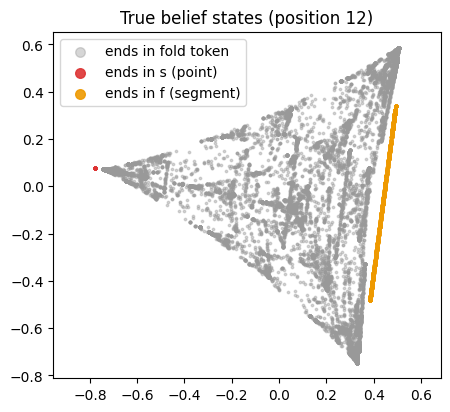

In [4]:
hmm = make("sync_strata", dest_emission=True)
print("token ranks:", {k: int(v) for k, v in zip(hmm.token_names, hmm.token_ranks())})
print("predicted stratum dimension (rank-1):", {k: int(v) for k, v in zip(hmm.token_names, hmm.stratum_dims())})
print("stationary distribution:", hmm.stationary().round(3))

# True Bayes beliefs at one position, projected on their two leading principal components.
toks, _ = exact.sample(hmm, 20000, 16, np.random.default_rng(0))
eta, probs, _ = exact.beliefs(hmm, toks)
t = 12
B = eta[:, t]
C = B - B.mean(0)
u, s, vt = np.linalg.svd(C, full_matrices=False)
P2 = C @ vt[:2].T
last = toks[:, t]
plt.figure(figsize=(5, 4.5))
for name, tok, col in [("ends in fold token", None, "#999"), ("ends in s (point)", 4, "#d33"), ("ends in f (segment)", 5, "#e90")]:
    m = (last < 4) if tok is None else (last == tok)
    plt.scatter(P2[m, 0], P2[m, 1], s=3, alpha=0.4 if tok is None else 0.9, c=col, label=name)
plt.legend(markerscale=4); plt.title("True belief states (position 12)"); plt.axis("equal"); plt.show()

## 2. Unit tests of the exact tools

Sampling frequencies match the analytic predictions, the Bayes predictor's cross-entropy equals its own
entropy, the belief after `s` is a single point, and the error-inheritance Jacobian matches a finite
difference and separates a synthetic recursive estimator from a parallel one.

In [5]:
import unittest
suite = unittest.defaultTestLoader.discover("hmmstrata_pkg/tests", pattern="test_*.py")
result = unittest.TextTestRunner(verbosity=1).run(suite)
assert result.wasSuccessful()

.

.

.

.

.

.

.

.

.

----------------------------------------------------------------------
Ran 9 tests in 1.214s

OK


## 3. Train

Fresh sequences every step (no fixed dataset), context 16, batch 128, AdamW lr 1e-3, weight decay 0, cosine
decay to 0, no warmup. Checkpoints are log-spaced from step 0.

In [6]:
from hmmstrata.train import train
RUNS = {}
for seed in SEEDS:
    out = Path(f"runs/seed{seed}")
    t0 = time.time()
    n_params = train("sync_strata", {"dest_emission": True}, seed, STEPS, out, DEV, wd=0.0, n_ckpt=24)
    RUNS[seed] = out
    print(f"seed {seed}: {n_params:,} parameters, {time.time() - t0:.0f} s")

seed 0: 143,846 parameters, 79 s


## 4. Surface and geometry at the final checkpoint

* **Excess KL**: `KL(Bayes || model)` averaged over positions, in 10^-3 nats.
* **Probe R²**: a linear map from the final residual stream to the true belief, on held-out sequences.
* **Point ratio**: total variance of the residual vectors at contexts ending in `s`, divided by the same for
  contexts ending in fold token 0 at least 5 steps after a sync (the control that holds the last token fixed),
  each centred per position and averaged over positions 6 to 14.

Shipped results for 3 seeds (this configuration, 40k steps):

| seed | excess KL (1e-3) | probe R² | point ratio |
|---|---|---|---|
| 0 | 0.087 | 0.9965 | 0.057 |
| 1 | 0.085 | 0.9963 | 0.030 |
| 2 | 0.082 | 0.9958 | 0.059 |

Fast mode (5,000 steps) is not converged: expect an excess KL of roughly 0.4 x 10^-3 and a looser point ratio of
about 0.1 to 0.15. Use `full` to match the table.

The earlier write-up reported a point ratio of 0.056 and an excess KL of about 0.08 x 10^-3 after correcting a
bug of its own (an untrained position in its analysis). Emitting fold tokens from the source state instead of
the destination state gave a ratio of 0.09 to 0.20, so the emission convention matters.

In [7]:
from hmmstrata.analyze import analyze
live = {}
for seed, run in RUNS.items():
    a = analyze(run, dev=DEV)
    live[seed] = a
    print(f"seed {seed}: excess KL {1e3*a['excess_kl_nats']:.3f}e-3 | probe R2 {a['probe_r2_all']:.4f} | "
          f"point ratio (pos 6-14) {a['point_ratio_perpos_6_14']:.3f}")
    print("   KL (1e-3) by steps since the last sync:", {k: round(v, 3) for k, v in a["kl_e3_by_since_sync"].items()})

seed 0: excess KL 0.374e-3 | probe R2 0.9940 | point ratio (pos 6-14) 0.133
   KL (1e-3) by steps since the last sync: {0: 0.252, 1: 0.362, 2: 0.483, 4: 0.456, 8: 0.53}


### Surplus history

The belief after `s` is a single point, so the token *before* the `s` carries no information about the future:
any decoding of it above the majority baseline is history the model keeps but does not need. The probe decodes
that token from the residual stream `k` steps after the `s`, at the final layer and at each layer for `k = 2`.

In [8]:
from hmmstrata.probes import evaluate
for seed, run in RUNS.items():
    r = evaluate(run, dev=DEV)
    print(f"seed {seed}: belief R2 by stream (embedding, layers 1-4):", " ".join(f"{v:.3f}" for v in r["belief_r2"]))
    print("  pre-sync token decoding, final layer (accuracy / majority baseline):")
    for k, (a, b, n) in r["presync_final"].items():
        print(f"    {k} steps after s: {a:.2f} / {b:.2f}")
    print("  k=2 by stream (embedding, L1..L4):", " ".join(f"{a:.2f}" for a, b in r["presync_layers"]))

seed 0: belief R2 by stream (embedding, layers 1-4): 0.751 0.948 0.982 0.990 0.993
  pre-sync token decoding, final layer (accuracy / majority baseline):
    1 steps after s: 0.89 / 0.24
    2 steps after s: 0.67 / 0.22
    3 steps after s: 0.52 / 0.24
    4 steps after s: 0.42 / 0.23
    6 steps after s: 0.31 / 0.23
    8 steps after s: 0.24 / 0.22
  k=2 by stream (embedding, L1..L4): 0.22 0.35 0.65 0.65 0.67


## 5. Learning order across training

For every checkpoint we measure KL, the belief-probe R² and the history decodable at `k = 2`. The answer to
"what is learned first" depends on the threshold, so the table gives the first checkpoint reaching fixed levels
(the grid is log-spaced and coarse):

| run | KL < 5e-3 | R² > 0.99 | KL < 1e-3 | history k=2 at 90% of its gain |
|---|---|---|---|---|
| dest0 | 633 | 3996 | 10041 | 10041 |
| dest1 | 633 | 3996 | 10041 | 10041 |
| dest2 | 399 | 3996 | 15918 | 10041 |
| control0 | 1003 | 3996 | 15918 | 3996 |
| control1 | 633 | 3996 | 15918 | 25233 |
| control2 | 633 | 3996 | 15918 | 6334 |
| control3 | 1003 | 3996 | 15918 | 10041 |
| control4 | 1590 | 3996 | 15918 | 6334 |

`dest*` are the destination-emission runs of this notebook, `control*` an earlier variant (source-state emission,
weight decay 0.01). Reading: the coarse surface comes first; the last order of magnitude of KL arrives after the
belief probe has saturated and together with the surplus history. Measured instead as "90% of the total KL
improvement on a linear scale", KL looks finished by step 16 to 40, which is an artefact of its huge starting
value and should not be quoted as "the surface settles first".

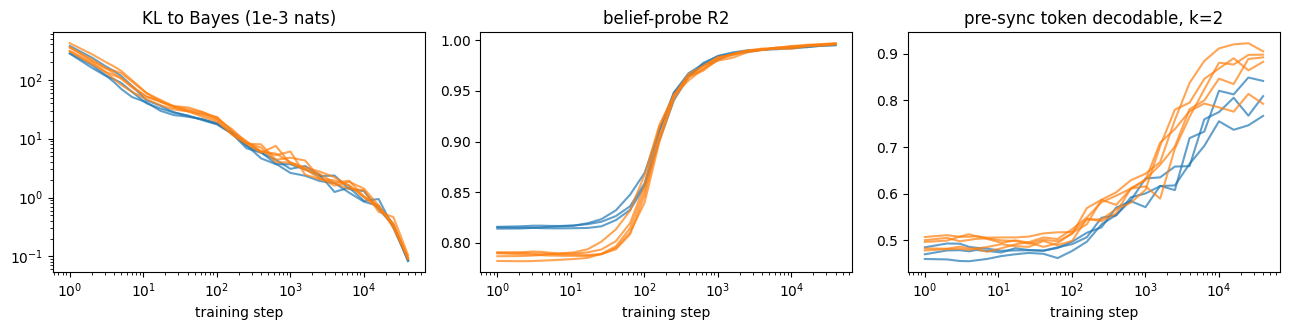

blue: destination-emission seeds (this notebook's setup), orange: earlier variant


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for name, o in RESULTS["series"].items():
    st = np.array([r["step"] for r in o]) + 1
    col = "C0" if name.startswith("dest") else "C1"
    ax[0].plot(st, [r["kl_e3"] for r in o], c=col, alpha=.7)
    ax[1].plot(st, [r["belief_r2"] for r in o], c=col, alpha=.7)
    ax[2].plot(st, [r["hist_k2"] for r in o], c=col, alpha=.7)
ax[0].set_yscale("log"); ax[0].set_title("KL to Bayes (1e-3 nats)")
ax[1].set_title("belief-probe R2"); ax[2].set_title("pre-sync token decodable, k=2")
for a in ax: a.set_xscale("log"); a.set_xlabel("training step")
plt.tight_layout(); plt.show()
print("blue: destination-emission seeds (this notebook's setup), orange: earlier variant")

In [10]:
# Optional: the same series for the model(s) trained above (takes a few minutes).
RUN_SERIES = False
if RUN_SERIES:
    from hmmstrata.series import series
    for seed, run in RUNS.items():
        o = series(run, n=8000, dev=DEV)
        print(seed, [(r["step"], round(r["kl_e3"], 3), round(r["belief_r2"], 3), round(r["hist_k2"], 2)) for r in o][::4])

## 6. Error inheritance

If a model folds recursively, so that its belief at `t+1` is the true update applied to its belief at `t`, then
its error at `t` is carried to `t+1` through the Jacobian of the update. If it computes each position afresh
from the context, the errors are unrelated. For pairs of positions at depth `k` after an `s`, followed by a fold
token, the score is the correlation between the probe error at `t+1` and the probe error at `t` pushed through
the true Jacobian, minus the same correlation with the `t+1` errors shuffled among the pairs.

Shipped final-checkpoint values (real minus shuffled; depths 1 to 6):

| seed | k=1 | k=2 | k=3 | k=4 | k=5 | k=6 |
|---|---|---|---|---|---|---|
| 0 | -0.08 | +0.02 | +0.08 | +0.10 | +0.13 | +0.15 |
| 1 | -0.16 | +0.01 | +0.07 | +0.07 | +0.04 | +0.04 |
| 2 | -0.10 | -0.06 | -0.05 | -0.03 | -0.03 | -0.01 |

At initialisation the score is about +0.4 to +0.5 at depths 3 to 5. It decays slowly during training. The final
models compute each position mostly afresh, with a weak residual inheritance on some seeds. Depth 1 is negative
on most seeds and unexplained.

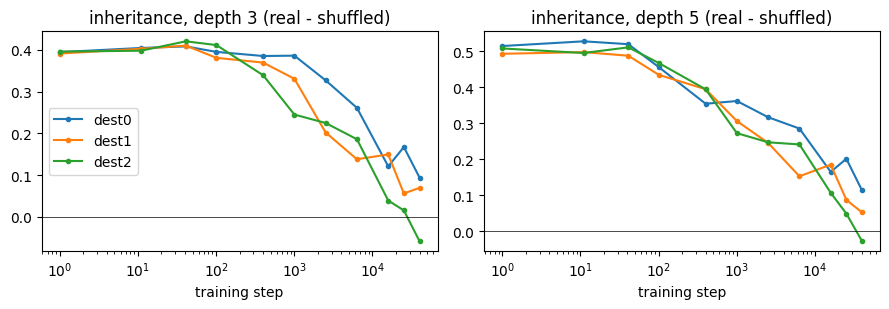

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for j, k in enumerate(("3", "5")):
    for s, d in RESULTS["inherit_dev"].items():
        st = sorted(int(x) for x in d)
        ax[j].plot(np.array(st) + 1, [d[str(x)][k][0] - d[str(x)][k][1] for x in st], marker="o", ms=3, label=s)
    ax[j].set_xscale("log"); ax[j].axhline(0, c="k", lw=.5); ax[j].set_title(f"inheritance, depth {k} (real - shuffled)")
    ax[j].set_xlabel("training step")
ax[0].legend(); plt.tight_layout(); plt.show()

In [12]:
from hmmstrata.inherit import inheritance
for seed, run in RUNS.items():
    r = inheritance(run, dev=DEV, n=30000)
    print(f"seed {seed}: real - shuffled by depth:", {k: round(v[0] - v[1], 3) for k, v in r.items()})

seed 0: real - shuffled by depth: {1: -0.075, 2: 0.138, 3: 0.215, 4: 0.187, 5: 0.182, 6: 0.209}


## 7. What did not work: local dimension of the residual stream

The natural way to look for "strata" in activations is a local-dimension estimator. We tried TwoNN and a
correlation-dimension slope on the residual stream. They did **not** discriminate the strata. The calibration
below uses synthetic sets of known dimension (0 to 3) with noise in 5 extra dimensions. TwoNN reads 7 to 9
whatever the true dimension, and the slopes drop to zero beyond the extent of the set, so a point and a short
segment look alike. Conclusions drawn from those estimators on the real activations would not be safe, and the
true belief geometry (computed from the HMM) is the reliable reference.

In [13]:
from hmmstrata.calibrate import synthetic
synthetic()

SYNTHETIC (noise: sigma=1 in 5 dims). cols: TwoNN MLE | slopes at 2,4,8,16,32 x NN


true d=0 L=  1   6.83  5.07 | 4.77±0.02 4.09±0.01 1.98±0.02 0.04±0.00 0.00±0.00


true d=1 L= 20   8.10  5.97 | 5.27±0.02 3.56±0.02 1.28±0.01 0.62±0.01 0.00±0.00


true d=1 L=100   8.01  5.88 | 4.80±0.03 2.58±0.02 1.16±0.01 0.96±0.00 0.82±0.00


true d=2 L= 20   9.23  6.69 | 5.44±0.02 3.09±0.02 1.69±0.01 0.46±0.01 0.00±0.00


true d=2 L=100   8.62  5.70 | 3.90±0.03 2.31±0.01 1.94±0.00 1.70±0.01 1.19±0.01


true d=3 L=100   7.37  4.41 | 3.51±0.02 2.96±0.01 2.64±0.01 2.03±0.01 0.25±0.02


## 8. Make the hidden state your own

A process is a token-labelled HMM: `T[x, i, j]` with `sum_x T[x]` row-stochastic, plus optional annotations
(named state groups, token and state events, an `expected` dictionary for predictions written down before
training). Register it by name and everything above runs unchanged. The example below makes the fold part
asymmetric (a different stay probability per state, keeping `s` and `f`). It is only constructed and checked
here; training and analysing it is the exercise.

In [14]:
import numpy as np
from hmmstrata.process import register, make
from hmmstrata.process.base import HMM

@register("sync_strata_asym")
def sync_strata_asym(stays=(0.95, 0.85, 0.7, 0.5), match=0.70, p_s=0.08, p_f=0.12):
    S, F = 4, 4
    V = F + 2
    p_fold = 1 - p_s - p_f
    M = np.zeros((S, S))
    for i, st in enumerate(stays):
        M[i] = (1 - st) / (S - 1); M[i, i] = st
    E = np.full((S, F), (1 - match) / (F - 1)); np.fill_diagonal(E, match)
    T = np.zeros((V, S, S))
    for x in range(F):
        T[x] = p_fold * M * E[:, x][None, :]            # destination emission
    T[F] = p_s * np.outer(np.ones(S), np.eye(S)[0])      # s: any state -> state 0 (rank 1)
    T[F + 1] = p_f * np.array([[0, .8, .2, 0]] * 2 + [[0, .2, .8, 0]] * 2)   # f: collapse to a segment (rank 2)
    h = HMM(name="sync_strata_asym", T=T, pi0=np.full(S, 1 / S), state_names=[f"q{i}" for i in range(S)],
            token_names=[str(i) for i in range(F)] + ["s", "f"], token_events={"s": {F}, "f": {F + 1}})
    h.pi0 = h.stationary()
    return h

h2 = make("sync_strata_asym")
print("ranks:", {k: int(v) for k, v in zip(h2.token_names, h2.token_ranks())})
print("stationary distribution:", h2.stationary().round(3), "(every state should keep non-trivial mass)")
# To train and analyse it:  train("sync_strata_asym", {}, seed, STEPS, Path("runs/asym"), DEV, wd=0.0)
# (hmmstrata.analyze looks up token names 's' and 'f', so it works for any process that keeps them.)

ranks: {'0': 4, '1': 4, '2': 4, '3': 4, 's': 1, 'f': 2}
stationary distribution: [0.467 0.333 0.148 0.052] (every state should keep non-trivial mass)


## 9. Limits

* One HMM, one architecture and context length, three seeds in the shipped results. Seeds disagree noticeably
  on the point ratio (0.03 to 0.06) and on how much history is retained.
* Probe-based measurements are only as good as the linear probe; the error-inheritance score goes through one.
* Every threshold in the learning-order table is a choice. The checkpoint grid is coarse.
* The point-stratum variance ratio measures spread, not dimension.
* The earlier variant (source-state emission) and this one differ, so numbers from the two must not be mixed.

## References

* Shai, Marzen, Teixeira, Gietelink Oldenziel, Riechers (2024). *Transformers represent belief state geometry in
  their residual stream.* https://arxiv.org/abs/2405.15943
* Piotrowski, Riechers, Filan, Shai (2025). *Constrained belief updates explain geometric structures in
  transformer representations.* https://arxiv.org/abs/2502.01954
* Robinson, Dey, Chiang (2025). *Token embeddings violate the manifold hypothesis.* https://arxiv.org/abs/2504.01002
* Robinson, Dey, Chiang (2024). *The structure of the token space for large language models.* https://arxiv.org/abs/2410.08993
* Wang et al. (2025). *Beyond the 80/20 Rule: High-Entropy Minority Tokens Drive Effective Reinforcement
  Learning for LLM Reasoning.* https://arxiv.org/abs/2506.01939

The setup follows an earlier private write-up produced with a Claude model; the destination-emission HMM, the
point-ratio definition and the surplus-history idea come from it. The checks here (position-15 artefact in the
original analysis, emission convention, learning order, inheritance, the failed dimension estimators) are ours.